# Segmentação de imagens por cor: de RGB para HSV

**Tutorial de teoria e prática (Projeto 2, Opção 2)**

| Nome completo | RA |
|---|---|
| João Guilherme Messias de Oliveira Santos | 10426110 |
| Luis Felipe Cunha | 10419514 |

Computação Visual, Turma 201815117.000.07N, Prof. André Kishimoto.
Ciência da Computação, Faculdade de Computação e Informática, Universidade Presbiteriana Mackenzie, 2026.2.

Vídeo-pitch do projeto: [youtube.com/watch?v=3PfPy9WShUE](https://www.youtube.com/watch?v=3PfPy9WShUE)

## Sumário

1. [Motivação](#secao1)
2. [Cor e o modelo RGB](#secao2)
3. [O modelo HSV e a conversão RGB → HSV](#secao3)
4. [Validação da conversão](#secao4)
5. [Segmentação por faixa de matiz](#secao5)
6. [Comparação: a mesma segmentação em RGB](#secao6)
7. [Limitações](#secao7)
8. [Conclusão](#secao8)
9. [Uso de IA](#secao9)
10. [Referências](#secao10)

## Preparação

Bibliotecas usadas no tutorial. O NumPy guarda as imagens como matrizes, o Matplotlib desenha as imagens e os gráficos e o Pillow abre os arquivos. A conversão de cor e a segmentação não usam funções prontas: estão implementadas no próprio notebook, nas próximas seções.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 100
# Figuras em JPEG deixam o notebook bem menor (em PNG ele passa de 6 MB)
%config InlineBackend.figure_formats = ["jpeg"]

<a id="secao1"></a>

## 1. Motivação

Até agora, na disciplina, trabalhamos só com escala de cinza. No Projeto 1 a imagem era convertida para cinza antes do histograma e da equalização, e nos posts do blog fizemos transformações ponto a ponto, suavização e limiarização. A limiarização já separa objeto e fundo, mas pelo brilho: escolhemos um valor e dividimos os pixels entre os mais claros e os mais escuros.

Neste projeto queremos separar um objeto pela cor, algo como "pegar só o objeto vermelho da foto". Com a imagem em cinza isso não funciona, e a imagem de teste abaixo mostra por quê.

### Imagem de teste sintética

Antes das fotos, geramos uma imagem pelo próprio código. Como sabemos onde cada objeto foi desenhado, ela vem com um gabarito, que mais adiante usamos para medir com números o acerto de cada segmentação.

A cena tem:

- quatro objetos (um círculo vermelho, um quadrado verde, um círculo azul e um quadrado cinza), com cores escolhidas para dar quase o mesmo tom de cinza
- fundo bege claro
- uma iluminação que escurece um pouco da esquerda para a direita
- uma sombra na parte de baixo, que corta todos os objetos ao meio
- um pouco de ruído, como numa foto de verdade

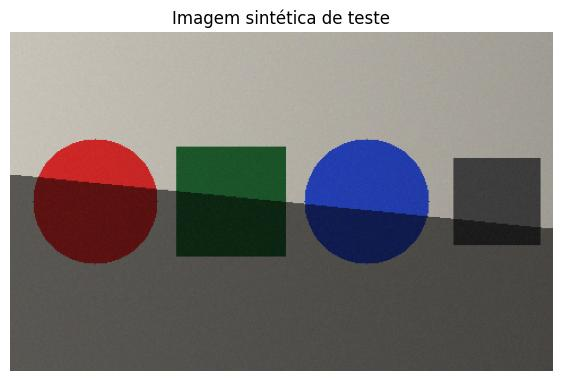

In [2]:
def cria_imagem_sintetica(altura=300, largura=480, semente=0):
    """Devolve a imagem RGB (uint8), o gabarito de cada objeto e a máscara da sombra."""
    y, x = np.mgrid[0:altura, 0:largura]

    cores = {
        "vermelho": (210, 40, 40),
        "verde": (30, 92, 45),
        "azul": (40, 70, 200),
        "cinza": (75, 75, 75),
    }
    gabarito = {
        "vermelho": (x - 75) ** 2 + (y - 150) ** 2 <= 55 ** 2,
        "verde": (np.abs(x - 195) <= 48) & (np.abs(y - 150) <= 48),
        "azul": (x - 315) ** 2 + (y - 150) ** 2 <= 55 ** 2,
        "cinza": (np.abs(x - 430) <= 38) & (np.abs(y - 150) <= 38),
    }

    img = np.empty((altura, largura, 3))
    img[:] = (200, 195, 185)
    for nome, cor in cores.items():
        img[gabarito[nome]] = cor

    # Luz e sombra multiplicam os três canais pelo mesmo fator, como acontece na prática
    sombra = y > 150 + 0.1 * (x - 240)
    fator = (1.0 - 0.2 * x / (largura - 1)) * np.where(sombra, 0.45, 1.0)
    img *= fator[..., None]

    rng = np.random.default_rng(semente)
    img += rng.normal(0, 3, img.shape)
    return np.clip(np.round(img), 0, 255).astype(np.uint8), gabarito, sombra


img_sint, gabarito, sombra = cria_imagem_sintetica()

plt.figure(figsize=(7, 4.5))
plt.imshow(img_sint)
plt.title("Imagem sintética de teste")
plt.axis("off")
plt.show()

### Tentando com a escala de cinza

A conversão para cinza usa a mesma fórmula do Projeto 1:

$$Y = 0{,}2125\,R + 0{,}7154\,G + 0{,}0721\,B$$

Em seguida aplicamos um limiar, como no post de limiarização do blog: todo pixel com valor menor que 100 vira objeto.

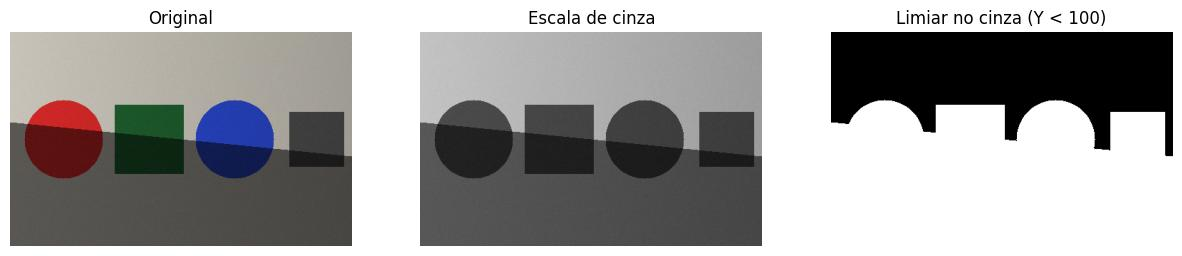

Tom de cinza médio de cada objeto (parte iluminada):
  vermelho    73.7
  verde       69.3
  azul        63.4
  cinza       61.5


In [3]:
def para_cinza(img):
    rgb = img.astype(float)
    return 0.2125 * rgb[..., 0] + 0.7154 * rgb[..., 1] + 0.0721 * rgb[..., 2]


cinza = para_cinza(img_sint)
mascara_cinza = cinza < 100

fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
eixos[0].imshow(img_sint)
eixos[0].set_title("Original")
eixos[1].imshow(cinza, cmap="gray", vmin=0, vmax=255)
eixos[1].set_title("Escala de cinza")
eixos[2].imshow(mascara_cinza, cmap="gray")
eixos[2].set_title("Limiar no cinza (Y < 100)")
for eixo in eixos:
    eixo.axis("off")
plt.show()

print("Tom de cinza médio de cada objeto (parte iluminada):")
for nome, regiao in gabarito.items():
    print(f"  {nome:9s} {cinza[regiao & ~sombra].mean():6.1f}")

Em cinza, os quatro objetos ficam com tons parecidos, entre 60 e 80. Qualquer limiar que pegue o vermelho pega também o verde, e o limiar de 100 ainda marca a sombra do fundo como objeto.

O que distingue os objetos é a cor, e essa informação some quando os três canais viram um número só. Por isso, daqui em diante trabalhamos com os três canais, primeiro em RGB e depois em HSV.

<a id="secao2"></a>

## 2. Cor e o modelo RGB

### Teoria

Na aula de Fundamentos da Imagem Digital vimos que a luz visível vai de cerca de 400 nm (violeta) a 700 nm (vermelho) e que a cor de um objeto depende dos comprimentos de onda que ele reflete. No olho, quem percebe a cor são os cones da retina.

Há três tipos de cone, cada um mais sensível a uma faixa que percebemos como vermelho, verde ou azul (GONZALEZ; WOODS, 2010, cap. 6). Misturando três luzes primárias, R (vermelho), G (verde) e B (azul), dá para reproduzir a maior parte das cores que enxergamos. O modelo RGB, usado em câmeras e telas, parte dessa ideia.

- O modelo é aditivo. Partimos do preto, sem luz nenhuma, e somamos luz: vermelho com verde dá amarelo, e os três no máximo dão branco.
- Cada canal costuma ter 8 bits, com valores de 0 a 255, o que dá $256^3 = 16.777.216$ cores.
- As cores podem ser vistas como pontos dentro de um cubo, com um canal em cada eixo. O preto $(0,0,0)$ fica num canto e o branco $(255,255,255)$ no canto oposto. Na diagonal entre os dois, onde $R = G = B$, ficam os tons de cinza.

No computador, uma imagem RGB é uma matriz `altura × largura × 3`, com três números por pixel.

### Prática: os três canais

In [4]:
print("Formato da imagem:", img_sint.shape, "| tipo:", img_sint.dtype)
print("Pixel (linha 120, coluna 75), no círculo vermelho iluminado:", img_sint[120, 75])
print("Pixel (linha 120, coluna 300), no círculo azul iluminado:   ", img_sint[120, 300])

Formato da imagem: (300, 480, 3) | tipo: uint8
Pixel (linha 120, coluna 75), no círculo vermelho iluminado: [207  37  40]
Pixel (linha 120, coluna 300), no círculo azul iluminado:    [ 33  61 174]


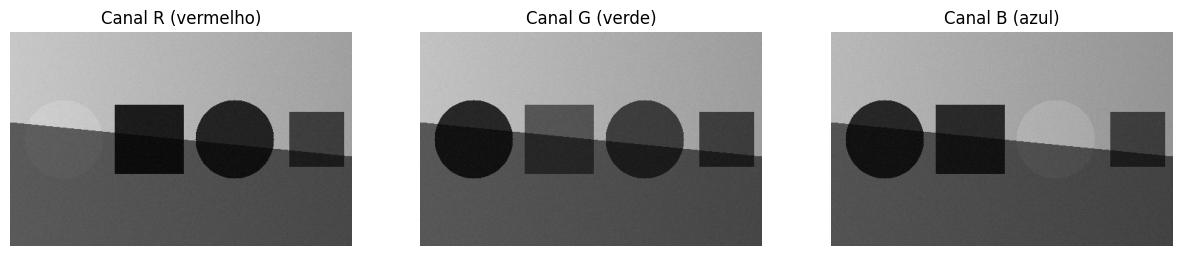

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
for c, (eixo, nome) in enumerate(zip(eixos, ["R (vermelho)", "G (verde)", "B (azul)"])):
    eixo.imshow(img_sint[..., c], cmap="gray", vmin=0, vmax=255)
    eixo.set_title(f"Canal {nome}")
    eixo.axis("off")
plt.show()

Cada canal, sozinho, é uma imagem em escala de cinza. O círculo vermelho aparece claro no canal R e escuro no G e no B, e o círculo azul só aparece claro no B. No canal R, a metade do círculo vermelho que está na sombra fica quase tão escura quanto o fundo sombreado.

### A limitação do RGB: a sombra muda os três canais

Uma sombra, ou uma luz mais fraca, diminui a luz que chega ao objeto. Na imagem, isso multiplica os três canais por um mesmo fator $k < 1$:

$$(R, G, B) \;\rightarrow\; (k\,R,\; k\,G,\; k\,B)$$

A proporção entre os canais, que é o que nos faz chamar uma cor de vermelha, continua igual, mas os valores dos três canais caem juntos. A tabela abaixo mede isso nos objetos da imagem sintética.

In [6]:
print(f"{'região':28s} {'R':>6s} {'G':>6s} {'B':>6s}")
for nome in ["vermelho", "verde", "azul"]:
    for parte, onde in [("iluminado", ~sombra), ("na sombra", sombra)]:
        r, g, b = img_sint[gabarito[nome] & onde].mean(axis=0)
        print(f"{nome + ' ' + parte:28s} {r:6.1f} {g:6.1f} {b:6.1f}")

fundo = ~np.any(list(gabarito.values()), axis=0)
r, g, b = img_sint[fundo & sombra].mean(axis=0)
print(f"{'fundo na sombra':28s} {r:6.1f} {g:6.1f} {b:6.1f}")

região                            R      G      B
vermelho iluminado            203.1   38.8   38.8
vermelho na sombra             91.6   17.5   17.4
verde iluminado                27.6   84.5   41.2
verde na sombra                12.4   38.0   18.7
azul iluminado                 34.8   60.8  173.7
azul na sombra                 15.8   27.3   78.3
fundo na sombra                81.1   79.1   75.0


Na sombra, o R do vermelho (cerca de 90) ficou mais perto do R do fundo sombreado (cerca de 80) do que do R do próprio vermelho no claro (cerca de 200). Uma regra como "é vermelho se R > 150" perde metade do objeto.

No gráfico abaixo, cada pixel dos objetos é um ponto no plano R × G. O B ficou de fora para o desenho caber em duas dimensões. A linha tracejada vai da origem (o preto) até a cor média da parte iluminada de cada objeto. Cada objeto forma dois grupos de pontos sobre a mesma linha: o mais longe da origem é a parte iluminada, e o mais perto é a parte na sombra. Numa foto a sombra costuma ser gradual, e o espaço entre os grupos se enche de pontos até formar uma faixa contínua.

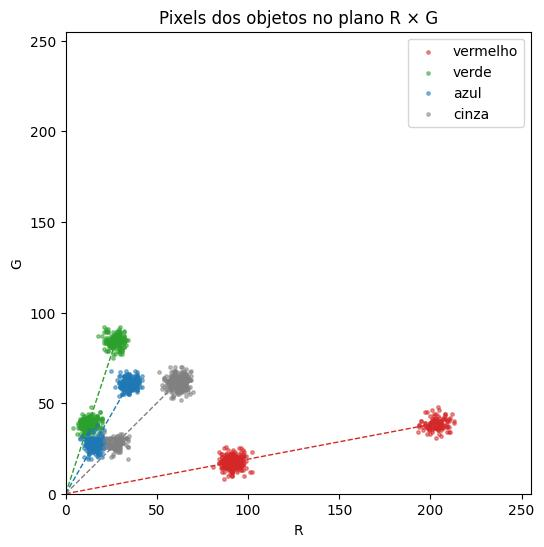

In [7]:
rng = np.random.default_rng(1)
cores_grafico = {"vermelho": "tab:red", "verde": "tab:green", "azul": "tab:blue", "cinza": "gray"}

plt.figure(figsize=(6, 6))
for nome, cor in cores_grafico.items():
    pixels = img_sint[gabarito[nome]]
    amostra = pixels[rng.choice(len(pixels), 400, replace=False)]
    plt.scatter(amostra[:, 0], amostra[:, 1], s=6, color=cor, alpha=0.5, label=nome)
    media_iluminada = img_sint[gabarito[nome] & ~sombra].mean(axis=0)
    plt.plot([0, media_iluminada[0]], [0, media_iluminada[1]], "--", color=cor, linewidth=1)
plt.xlim(0, 255)
plt.ylim(0, 255)
plt.xlabel("R")
plt.ylabel("G")
plt.title("Pixels dos objetos no plano R × G")
plt.legend()
plt.show()

Em RGB, então, uma cor ocupa uma faixa diagonal que desce até o preto. Para isolar o vermelho seria preciso descrever essa faixa inclinada, e um limiar em cada canal só descreve caixas alinhadas aos eixos. Perto da origem a situação piora, porque os grupos de cores diferentes se aproximam (compare o azul, o verde e o cinza na sombra).

O ideal seria ter um número para dizer qual é a cor e outro para dizer o quanto ela está clara. O modelo HSV faz essa separação.

<a id="secao3"></a>

## 3. O modelo HSV e a conversão RGB → HSV

### Teoria: matiz, saturação e valor

Alvy Ray Smith propôs o modelo HSV em 1978 (SMITH, 1978) para descrever as cores de um jeito mais parecido com o que as pessoas usam quando falam delas. No lugar de "quanto de vermelho, de verde e de azul", a cor é descrita por:

- H (*hue*, matiz): qual é a cor. É um ângulo de 0° a 360° numa roda de cores, com 0° no vermelho, 60° no amarelo, 120° no verde, 180° no ciano, 240° no azul e 300° no magenta. Passando de 360°, a roda volta ao vermelho.
- S (*saturation*, saturação): o quanto a cor é pura, de 0 a 1. S = 0 é cinza, e S = 1 é uma cor sem nenhum cinza misturado.
- V (*value*, valor): o quanto a cor é clara, de 0 a 1. V = 0 é preto.

Smith descreveu o HSV como um cone de base hexagonal (*hexcone*). O V é a altura, o S é a distância até o eixo central e o H é o ângulo em volta desse eixo. O eixo central, onde S = 0, corresponde à diagonal de cinzas do cubo RGB.

A figura abaixo mostra o plano H × S com V = 1. Para desenhá-la usamos a função `hsv_to_rgb` do Matplotlib, que faz o caminho inverso (HSV → RGB), só como ilustração. A conversão usada no resto do tutorial é a que está implementada mais abaixo.

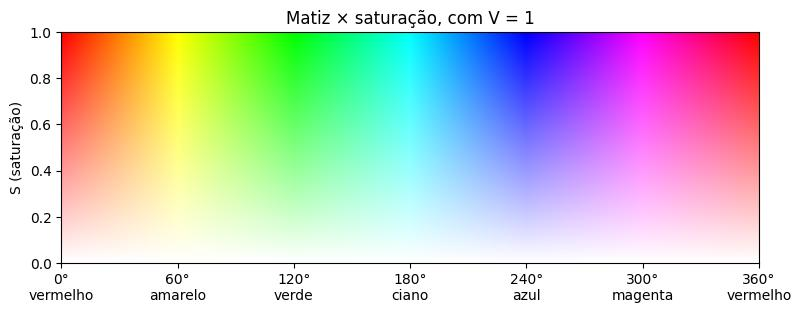

In [8]:
from matplotlib.colors import hsv_to_rgb

h_plano, s_plano = np.meshgrid(np.linspace(0, 1, 361), np.linspace(0, 1, 101))
plano = hsv_to_rgb(np.stack([h_plano, s_plano, np.ones_like(h_plano)], axis=-1))

plt.figure(figsize=(9, 3))
plt.imshow(plano, origin="lower", extent=[0, 360, 0, 1], aspect="auto")
plt.xticks(range(0, 361, 60), ["0°\nvermelho", "60°\namarelo", "120°\nverde",
                               "180°\nciano", "240°\nazul", "300°\nmagenta", "360°\nvermelho"])
plt.ylabel("S (saturação)")
plt.title("Matiz × saturação, com V = 1")
plt.show()

O que interessa para a segmentação: quando a sombra multiplica $(R, G, B)$ por $k$, só o V muda. O H e o S dependem das proporções entre os canais, que a sombra não altera, e as fórmulas mostram por quê.

### As fórmulas da conversão

Primeiro dividimos $R$, $G$ e $B$ por 255, para os valores ficarem entre 0 e 1. Depois calculamos (SMITH, 1978; GONZALEZ; WOODS, 2010):

$$V = \max(R, G, B)$$

$$C = \max(R, G, B) - \min(R, G, B)$$

$$S = \begin{cases} C / V & \text{se } V > 0 \\ 0 & \text{se } V = 0 \end{cases}$$

$$H = 60° \times \begin{cases}
\left(\dfrac{G - B}{C}\right) \bmod 6 & \text{se } \max = R \\[2ex]
\dfrac{B - R}{C} + 2 & \text{se } \max = G \\[2ex]
\dfrac{R - G}{C} + 4 & \text{se } \max = B
\end{cases}
\qquad (H = 0 \text{ se } C = 0)$$

O papel de cada termo:

- V é o canal mais forte.
- C (croma) é a distância entre o canal mais forte e o mais fraco. Com os três canais iguais, $C = 0$ e o pixel é cinza.
- S é o croma em relação ao brilho. A sombra não muda o S porque, multiplicando tudo por $k$, $C$ e $V$ também são multiplicados por $k$, e o $k$ some na divisão.
- H começa pelo canal dominante, que diz em que terço da roda a cor está: vermelho perto de 0°, verde perto de 120° (o $+2$, já que $2 \times 60° = 120°$) e azul perto de 240° (o $+4$). A fração desloca o ângulo para um lado ou para o outro, conforme qual dos outros dois canais é maior. O $\bmod 6$ só age no caso do vermelho: quando $B > G$ a fração é negativa, e o $\bmod$ leva o resultado para perto de 360°, um vermelho puxado para o magenta. No H o $k$ da sombra também se cancela, porque multiplica o numerador e o denominador.
- Com $C = 0$ não há matiz, já que cinza não tem cor. Por convenção, usamos $H = 0$.

### Exemplo feito à mão

Um vermelho iluminado $(200, 50, 50)$ e o mesmo vermelho na sombra, com $k = 0{,}5$: $(100, 25, 25)$.

| | $R, G, B$ (÷255) | $V$ | $C$ | $S = C/V$ | $H$ |
|---|---|---|---|---|---|
| iluminado | 0,784 · 0,196 · 0,196 | 0,784 | 0,588 | **0,75** | $60 \times (0/0{,}588 \bmod 6) =$ **0°** |
| na sombra | 0,392 · 0,098 · 0,098 | 0,392 | 0,294 | **0,75** | $60 \times (0/0{,}294 \bmod 6) =$ **0°** |

H e S saem iguais nos dois casos, e só o V cai pela metade. A seguir, as fórmulas viram código.

### Prática 1: conversão de um pixel

A primeira versão segue as fórmulas linha a linha e converte um pixel por vez:

In [9]:
def rgb_para_hsv_pixel(r, g, b):
    """Converte um pixel RGB (0 a 255) para (H em graus, S de 0 a 1, V de 0 a 1)."""
    r, g, b = r / 255, g / 255, b / 255
    maximo = max(r, g, b)
    minimo = min(r, g, b)
    c = maximo - minimo

    v = maximo
    s = 0.0 if v == 0 else c / v

    if c == 0:
        h = 0.0
    elif maximo == r:
        h = 60 * (((g - b) / c) % 6)
    elif maximo == g:
        h = 60 * ((b - r) / c + 2)
    else:
        h = 60 * ((r - g) / c + 4)
    return h, s, v


for nome, pixel in [("vermelho iluminado", (200, 50, 50)), ("vermelho na sombra", (100, 25, 25)),
                    ("vermelho puxando p/ magenta", (200, 50, 80)), ("verde", (30, 92, 45)),
                    ("azul", (40, 70, 200)), ("cinza", (75, 75, 75))]:
    h, s, v = rgb_para_hsv_pixel(*pixel)
    print(f"{nome:28s} {str(pixel):16s} -> H = {h:6.1f}°  S = {s:.3f}  V = {v:.3f}")

vermelho iluminado           (200, 50, 50)    -> H =    0.0°  S = 0.750  V = 0.784
vermelho na sombra           (100, 25, 25)    -> H =    0.0°  S = 0.750  V = 0.392
vermelho puxando p/ magenta  (200, 50, 80)    -> H =  348.0°  S = 0.750  V = 0.784
verde                        (30, 92, 45)     -> H =  134.5°  S = 0.674  V = 0.361
azul                         (40, 70, 200)    -> H =  228.8°  S = 0.800  V = 0.784
cinza                        (75, 75, 75)     -> H =    0.0°  S = 0.000  V = 0.294


A saída confere com a conta feita à mão. Dois casos chamam atenção:

- O vermelho com um pouco mais de azul, $(200, 50, 80)$, deu $H = 348°$, por causa do $\bmod 6$ que dá a volta na roda. Como números, 348 e 0 estão longe, mas como cores são vizinhos, e a segmentação vai ter que levar isso em conta.
- O cinza tem $S = 0$ e $H = 0$ pela convenção, e esse $H = 0$ não quer dizer vermelho.

### Prática 2: conversão da imagem inteira com NumPy

A imagem sintética tem $300 \times 480 = 144.000$ pixels, e uma foto de celular tem milhões. Chamar a função acima dentro de um `for` funciona, mas em Python fica lento. Com NumPy, cada operação é aplicada na matriz inteira de uma vez:

- `max` e `min` com `axis=-1` dão o maior e o menor canal de cada pixel.
- No $S$, `np.divide(..., where=v > 0)` divide só onde $V > 0$ e deixa 0 no resto.
- No $H$, calculamos as três fórmulas para todos os pixels, e `np.select` escolhe a certa para cada pixel. As condições seguem a ordem da versão de um pixel: primeiro $C = 0$, depois máximo em R, depois em G e, se nenhuma valer, B.
- Onde $C = 0$, o divisor vira 1 (`c_seguro`) só para evitar a divisão por zero. O `np.select` descarta esses resultados de qualquer jeito.

In [10]:
def rgb_para_hsv(img):
    """Converte uma imagem RGB uint8 (altura x largura x 3) para HSV.
    Devolve uma matriz float com H em graus [0, 360), S e V em [0, 1]."""
    rgb = img.astype(np.float64) / 255
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    maximo = rgb.max(axis=-1)
    minimo = rgb.min(axis=-1)
    c = maximo - minimo

    v = maximo
    s = np.divide(c, v, out=np.zeros_like(c), where=v > 0)

    c_seguro = np.where(c > 0, c, 1)
    h_r = 60 * (((g - b) / c_seguro) % 6)
    h_g = 60 * ((b - r) / c_seguro + 2)
    h_b = 60 * ((r - g) / c_seguro + 4)
    h = np.select([c == 0, maximo == r, maximo == g], [0.0, h_r, h_g], default=h_b)

    return np.stack([h, s, v], axis=-1)

In [11]:
import time

inicio = time.perf_counter()
hsv_laco = np.array([[rgb_para_hsv_pixel(*map(int, px)) for px in linha] for linha in img_sint])
tempo_laco = time.perf_counter() - inicio

inicio = time.perf_counter()
hsv_sint = rgb_para_hsv(img_sint)
tempo_numpy = time.perf_counter() - inicio

print(f"Laço pixel a pixel: {tempo_laco * 1000:8.1f} ms")
print(f"NumPy (vetorizado): {tempo_numpy * 1000:8.1f} ms  ({tempo_laco / tempo_numpy:.0f}x mais rápido)")

Laço pixel a pixel:    251.0 ms
NumPy (vetorizado):     15.7 ms  (16x mais rápido)


Os tempos mudam de um computador para outro, mas a versão vetorizada fica sempre bem à frente. Na seção 4 conferimos que as duas versões dão o mesmo resultado.

### Prática 3: os canais H, S e V da imagem sintética

O H aparece com um mapa de cores circular (`hsv`, do Matplotlib), em que 0° e 360° têm a mesma cor. O S e o V aparecem em escala de cinza.

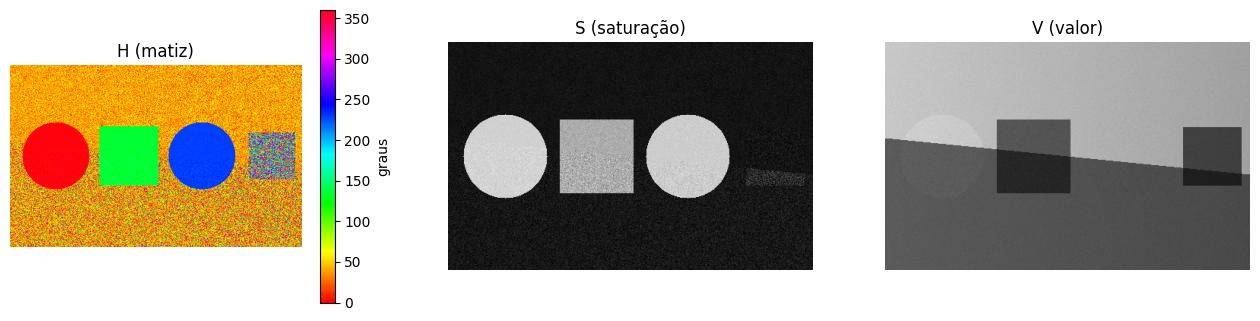

In [12]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 3.8))
im = eixos[0].imshow(hsv_sint[..., 0], cmap="hsv", vmin=0, vmax=360)
fig.colorbar(im, ax=eixos[0], label="graus")
eixos[0].set_title("H (matiz)")
eixos[1].imshow(hsv_sint[..., 1], cmap="gray", vmin=0, vmax=1)
eixos[1].set_title("S (saturação)")
eixos[2].imshow(hsv_sint[..., 2], cmap="gray", vmin=0, vmax=1)
eixos[2].set_title("V (valor)")
for eixo in eixos:
    eixo.axis("off")
plt.show()

No canal H, os círculos vermelho e azul e o quadrado verde têm matiz uniforme, e a sombra não aparece. O fundo bege sai alaranjado e granulado, já que bege é um laranja pouco saturado, e o quadrado cinza vira um chuvisco de cores. Nos dois casos o pixel é cinza ou quase cinza: com $C$ muito pequeno, o ruído decide qual canal é o maior, e a matiz pula de um valor para outro. Por isso a segmentação vai exigir uma saturação mínima.

No canal S, os três objetos coloridos aparecem claros (saturados), o fundo e o quadrado cinza aparecem escuros e a sombra quase some. A exceção é a metade sombreada do quadrado cinza, um pouco mais clara: num pixel escuro o ruído pesa mais em relação ao $V$ e cria uma saturação que a cor não tem. Daí a segunda exigência da segmentação, um valor mínimo.

No canal V a sombra aparece inteira. O brilho, que no RGB estava distribuído pelos três canais, ficou concentrado aqui.

Para conferir com números, medimos H, S e V de cada objeto na parte iluminada e na sombra. A média do H precisa de cuidado. Os pixels do vermelho ficam em volta de 0°, uns em 1° e outros em 359°, e a média aritmética cairia no meio da roda, longe do vermelho. Por isso usamos a média circular: cada ângulo vira um vetor de tamanho 1, tiramos a média dos vetores e pegamos o ângulo do resultado.

In [13]:
def media_circular(angulos_graus):
    rad = np.deg2rad(angulos_graus)
    return np.rad2deg(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360


print(f"{'região':28s} {'H (°)':>7s} {'S':>6s} {'V':>6s}   {'média simples de H':>18s}")
for nome in ["vermelho", "verde", "azul"]:
    for parte, onde in [("iluminado", ~sombra), ("na sombra", sombra)]:
        h, s, v = hsv_sint[gabarito[nome] & onde].T
        print(f"{nome + ' ' + parte:28s} {media_circular(h):7.1f} {s.mean():6.2f} {v.mean():6.2f}   {h.mean():18.1f}")

região                         H (°)      S      V   média simples de H
vermelho iluminado               0.0   0.82   0.80                159.9
vermelho na sombra               0.0   0.83   0.36                162.9
verde iluminado                134.3   0.67   0.33                134.3
verde na sombra                134.2   0.68   0.15                134.2
azul iluminado                 228.8   0.80   0.68                228.8
azul na sombra                 229.0   0.80   0.31                229.0


Comparando com a tabela RGB da seção 2: em RGB, a sombra derrubou os três canais para menos da metade. Em HSV mudou só o V, e o H e o S de cada objeto ficaram praticamente iguais. As pequenas diferenças vêm do ruído, que pesa mais quando o pixel está escuro.

A última coluna mostra o erro da média simples no vermelho, que dá cerca de 160° (entre verde e ciano) quando o certo é ~0°. Nos outros objetos, longe de 0°/360°, as duas médias coincidem.

Antes de usar essa conversão para segmentar, falta confirmar que ela está correta.

<a id="secao4"></a>

## 4. Validação da conversão

Uma conversão pode parecer certa nas figuras e errar em casos específicos, como empates entre canais, cinzas, o preto ou a volta dos 360°. Conferimos a implementação de quatro formas:

1. cores com HSV conhecido, testadas com `assert` (se alguma falhar, o notebook para com erro)
2. a versão de um pixel contra a versão vetorizada
3. a nossa conversão contra o módulo `colorsys`, da biblioteca padrão do Python
4. a nossa conversão contra a função `cv2.cvtColor` do OpenCV

O `colorsys` e o OpenCV aparecem aqui só como referência para medir o erro. A segmentação não usa nenhum dos dois.

### Teste 1: cores conhecidas

In [14]:
cores_conhecidas = [
    ("vermelho", (255, 0, 0), (0, 1, 1)),
    ("amarelo", (255, 255, 0), (60, 1, 1)),
    ("verde", (0, 255, 0), (120, 1, 1)),
    ("ciano", (0, 255, 255), (180, 1, 1)),
    ("azul", (0, 0, 255), (240, 1, 1)),
    ("magenta", (255, 0, 255), (300, 1, 1)),
    ("laranja", (255, 128, 0), (60 * 128 / 255, 1, 1)),
    ("vermelho escuro", (128, 0, 0), (0, 1, 128 / 255)),
    ("branco", (255, 255, 255), (0, 0, 1)),
    ("cinza", (128, 128, 128), (0, 0, 128 / 255)),
    ("preto", (0, 0, 0), (0, 0, 0)),
]

for nome, rgb, esperado in cores_conhecidas:
    obtido = rgb_para_hsv_pixel(*rgb)
    vetorizado = rgb_para_hsv(np.array([[rgb]], dtype=np.uint8))[0, 0]
    assert np.allclose(obtido, esperado) and np.allclose(vetorizado, esperado), nome
    print(f"{nome:16s} {str(rgb):16s} -> H = {obtido[0]:6.2f}°  S = {obtido[1]:.3f}  V = {obtido[2]:.3f}   ok")

vermelho         (255, 0, 0)      -> H =   0.00°  S = 1.000  V = 1.000   ok
amarelo          (255, 255, 0)    -> H =  60.00°  S = 1.000  V = 1.000   ok
verde            (0, 255, 0)      -> H = 120.00°  S = 1.000  V = 1.000   ok
ciano            (0, 255, 255)    -> H = 180.00°  S = 1.000  V = 1.000   ok
azul             (0, 0, 255)      -> H = 240.00°  S = 1.000  V = 1.000   ok
magenta          (255, 0, 255)    -> H = 300.00°  S = 1.000  V = 1.000   ok
laranja          (255, 128, 0)    -> H =  30.12°  S = 1.000  V = 1.000   ok
vermelho escuro  (128, 0, 0)      -> H =   0.00°  S = 1.000  V = 0.502   ok
branco           (255, 255, 255)  -> H =   0.00°  S = 0.000  V = 1.000   ok
cinza            (128, 128, 128)  -> H =   0.00°  S = 0.000  V = 0.502   ok
preto            (0, 0, 0)        -> H =   0.00°  S = 0.000  V = 0.000   ok


### Teste 2: versão de um pixel × versão vetorizada

Na seção 3 a imagem sintética foi convertida das duas formas (`hsv_laco` e `hsv_sint`). Se a vetorização estiver certa, as duas matrizes são iguais.

In [15]:
diferenca = np.abs(hsv_laco - hsv_sint).max()
print("Maior diferença entre as duas versões:", diferenca)
assert diferenca < 1e-12

Maior diferença entre as duas versões: 0.0


### Conjunto de teste para as bibliotecas

Para a comparação com as bibliotecas, juntamos um conjunto grande de cores:

- todos os pixels da imagem sintética (144.000)
- uma grade regular do cubo RGB com passo 15 em cada canal ($18^3 = 5.832$ cores, com preto, branco, cinzas e empates entre canais)
- 100.000 cores sorteadas

As cores vão numa matriz de uma linha só, porque as funções esperam receber uma "imagem".

O H é comparado pela diferença angular: 359,9° e 0,1° estão a 0,2° um do outro na roda, embora a diferença simples dê 359,8°.

In [16]:
def diferenca_angular(a, b):
    d = np.abs(a - b) % 360
    return np.minimum(d, 360 - d)


grade = np.arange(0, 256, 15)
cores_grade = np.stack(np.meshgrid(grade, grade, grade), axis=-1).reshape(-1, 3)
cores_sorteadas = np.random.default_rng(2).integers(0, 256, (100_000, 3))
cores_teste = np.vstack([img_sint.reshape(-1, 3), cores_grade, cores_sorteadas]).astype(np.uint8)

img_teste = cores_teste.reshape(1, -1, 3)
hsv_nosso = rgb_para_hsv(img_teste)[0]
print("Total de cores no teste:", len(cores_teste))


def relatorio(nome, h_ref, s_ref, v_ref):
    erros = {
        "H (graus)": diferenca_angular(hsv_nosso[:, 0], h_ref),
        "S": np.abs(hsv_nosso[:, 1] - s_ref),
        "V": np.abs(hsv_nosso[:, 2] - v_ref),
    }
    print(f"Nossa conversão × {nome}")
    print(f"  {'canal':10s} {'erro máximo':>14s} {'erro médio':>14s}")
    for canal, erro in erros.items():
        print(f"  {canal:10s} {erro.max():14.2e} {erro.mean():14.2e}")
    return erros

Total de cores no teste: 249832


### Teste 3: `colorsys`

O `colorsys.rgb_to_hsv` recebe um pixel com valores de 0 a 1 e devolve H, S e V também de 0 a 1. Multiplicamos o H dele por 360 para comparar com o nosso, que está em graus.

In [17]:
import colorsys

ref_colorsys = np.array([colorsys.rgb_to_hsv(*(px / 255)) for px in cores_teste.astype(float)])
erros_colorsys = relatorio("colorsys", ref_colorsys[:, 0] * 360, ref_colorsys[:, 1], ref_colorsys[:, 2])

assert all(erro.max() < 1e-9 for erro in erros_colorsys.values())

Nossa conversão × colorsys
  canal         erro máximo     erro médio
  H (graus)        1.14e-13       6.28e-15
  S                0.00e+00       0.00e+00
  V                0.00e+00       0.00e+00


Os erros ficam na ordem de $10^{-13}$, que é arredondamento de ponto flutuante. Na prática, os resultados são idênticos.

### Teste 4: OpenCV

O `cv2.cvtColor` tem dois modos:

- Com imagem `float32` (valores de 0 a 1), devolve H de 0 a 360 e S e V de 0 a 1, na mesma escala da nossa conversão.
- Com imagem `uint8` (0 a 255), o H precisa caber em 8 bits. Como 360 passa de 255, o OpenCV guarda H/2 (0 a 179), e S e V vão de 0 a 255. Quem copia limiares de tutoriais do OpenCV precisa lembrar disso: "H = 90" no modo `uint8` é 180°, ciano.

In [18]:
import cv2

ref_cv = cv2.cvtColor((img_teste / 255).astype(np.float32), cv2.COLOR_RGB2HSV)[0].astype(np.float64)
erros_cv = relatorio("OpenCV (float32)", ref_cv[:, 0], ref_cv[:, 1], ref_cv[:, 2])

assert erros_cv["H (graus)"].max() < 0.01
assert erros_cv["S"].max() < 1e-5 and erros_cv["V"].max() < 1e-5

Nossa conversão × OpenCV (float32)
  canal         erro máximo     erro médio
  H (graus)        1.83e-03       7.03e-05
  S                3.40e-06       9.40e-08
  V                2.97e-08       1.22e-08


O erro aqui é maior que no `colorsys`, mas continua muito pequeno: no máximo milésimos de grau no H. A diferença vem da precisão. O OpenCV calcula em `float32`, com cerca de 7 dígitos significativos, e nós em `float64`, com cerca de 16. Um erro de 0,002° no H não aparece em imagem nenhuma.

Por último, o modo `uint8`. Passamos o nosso resultado para a escala do OpenCV (H/2 e S, V × 255) e comparamos:

In [19]:
ref_cv8 = cv2.cvtColor(img_teste, cv2.COLOR_RGB2HSV)[0].astype(np.float64)
print("Faixa do OpenCV uint8 (mín, máx):  H", ref_cv8[:, 0].min(), ref_cv8[:, 0].max(),
      "| S", ref_cv8[:, 1].min(), ref_cv8[:, 1].max(), "| V", ref_cv8[:, 2].min(), ref_cv8[:, 2].max())

nosso_na_escala_cv = np.stack([hsv_nosso[:, 0] / 2, hsv_nosso[:, 1] * 255, hsv_nosso[:, 2] * 255], axis=-1)
dif_h = np.abs(nosso_na_escala_cv[:, 0] - ref_cv8[:, 0])
dif_h = np.minimum(dif_h, 180 - dif_h)
dif_s = np.abs(nosso_na_escala_cv[:, 1] - ref_cv8[:, 1])
dif_v = np.abs(nosso_na_escala_cv[:, 2] - ref_cv8[:, 2])
print(f"Maior diferença (em unidades do OpenCV uint8):  H {dif_h.max():.2f}   S {dif_s.max():.2f}   V {dif_v.max():.2f}")

assert dif_h.max() < 1 and dif_s.max() < 1 and dif_v.max() < 1

Faixa do OpenCV uint8 (mín, máx):  H 0.0 179.0 | S 0.0 255.0 | V 0.0 255.0
Maior diferença (em unidades do OpenCV uint8):  H 0.62   S 0.52   V 0.00


As diferenças ficam abaixo de 1 unidade e vêm do arredondamento para inteiro que o modo `uint8` faz.

### Resumo da validação

| Teste | Resultado |
|---|---|
| Cores conhecidas (11 casos, incluindo preto, branco e cinza) | todas corretas |
| Versão de um pixel × versão vetorizada | idênticas |
| × `colorsys` (~250 mil cores) | erro ~$10^{-13}$, idênticas |
| × OpenCV `float32` | erro de milésimos de grau, por causa da precisão `float32` |
| × OpenCV `uint8` | diferença < 1 unidade, por causa do arredondamento para inteiro |

Todos os testes usam `assert`. Se alguém mudar a função e introduzir um erro, o notebook para nesta seção. Com a conversão validada, passamos à segmentação.

<a id="secao5"></a>

## 5. Segmentação por faixa de matiz

### Teoria: do limiar simples para uma faixa de cor

Na limiarização em escala de cinza, assunto do post 08 do blog, a regra era um número só: o pixel é objeto se $I(x, y) < T$. O resultado é uma máscara binária, uma imagem do tamanho da original em que cada pixel vale verdadeiro (objeto) ou falso (fundo).

Em HSV a ideia é a mesma, com uma regra que usa os três canais. Um pixel é do objeto se:

$$h_{min} \le H \le h_{max} \quad\text{e}\quad S \ge s_{min} \quad\text{e}\quad V \ge v_{min}$$

- A faixa de matiz $[h_{min}, h_{max}]$ define qual cor queremos e é a parte principal da regra.
- O $s_{min}$ tira os pixels quase cinza. Na seção 3, com saturação baixa, o $C$ ficou tão pequeno que o ruído decidiu a matiz, e o fundo bege e o quadrado cinza viraram um chuvisco de cores. O H desses pixels não quer dizer nada, então eles ficam fora da máscara mesmo que o H caia por acaso dentro da faixa.
- O $v_{min}$ tira os pixels muito escuros, pelo mesmo motivo: perto do preto o ruído pesa mais e cria saturação e matiz.

A regra não tem limite máximo de V nem de S, e é isso que deixa a sombra entrar. A parte do objeto na sombra tem V menor, mas a matiz é a mesma.

### O caso do vermelho

A matiz é um ângulo, e o vermelho fica em cima do 0°: um vermelho pode ter $H = 5°$ e outro $H = 355°$. Uma faixa de 340° a 20° não pode ser escrita como $340 \le H \le 20$, porque nenhum número atende às duas condições. Quando $h_{min} > h_{max}$, a faixa passa pelo 0° e a regra vira um *ou*:

$$H \ge h_{min} \quad\text{ou}\quad H \le h_{max}$$

### Como escolher a faixa: o histograma de H

Na aula de Histograma, o histograma contava quantos pixels havia em cada nível de intensidade. Aqui fazemos o histograma do canal H, só com os pixels que passam pelos limites de $s_{min}$ e $v_{min}$, porque os outros não têm matiz confiável. Cada objeto colorido vira um pico, e a faixa de matiz é escolhida em volta do pico do objeto que queremos.

### Prática: as funções de segmentação

In [20]:
def segmentar_hsv(hsv, h_min, h_max, s_min=0.3, v_min=0.15):
    """Devolve a máscara (bool) dos pixels com H na faixa [h_min, h_max] (em graus),
    S >= s_min e V >= v_min. Se h_min > h_max, a faixa passa pelo 0° (caso do vermelho)."""
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    if h_min <= h_max:
        na_faixa = (h >= h_min) & (h <= h_max)
    else:
        na_faixa = (h >= h_min) | (h <= h_max)
    return na_faixa & (s >= s_min) & (v >= v_min)


# Teste com pixels conhecidos: (H, S, V)
pixels = np.array([[[5, 0.8, 0.8],     # vermelho
                    [355, 0.8, 0.8],   # vermelho do outro lado do 0°
                    [180, 0.8, 0.8],   # ciano
                    [5, 0.05, 0.8],    # quase cinza: H não confiável
                    [5, 0.8, 0.05]]])  # quase preto
print(segmentar_hsv(pixels, 340, 20)[0])
assert segmentar_hsv(pixels, 340, 20)[0].tolist() == [True, True, False, False, False]
assert segmentar_hsv(pixels, 0, 20)[0].tolist() == [True, False, False, False, False]

[ True  True False False False]


A faixa de 340° a 20° aceitou os dois vermelhos (5° e 355°) e recusou o ciano, o pixel quase cinza e o quase preto. Com a faixa de 0° a 20°, que não passa pelo 0°, o vermelho de 355° ficou de fora.

Em seguida vêm as funções de apoio: o histograma de H, com cada barra pintada da cor que representa, e uma figura que mostra, para cada máscara, a máscara e o objeto isolado (os pixels fora da máscara ficam pretos).

In [21]:
def histograma_h(hsv, s_min=0.3, v_min=0.15, eixo=None, titulo="Histograma de H"):
    """Histograma do canal H (bins de 5°) só com os pixels de S >= s_min e V >= v_min."""
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    confiaveis = (s >= s_min) & (v >= v_min)
    contagem, bordas = np.histogram(h[confiaveis], bins=72, range=(0, 360))
    centros = (bordas[:-1] + bordas[1:]) / 2
    cores = hsv_to_rgb(np.stack([centros / 360, np.ones(72), np.ones(72)], axis=-1))

    eixo = eixo or plt.gca()
    eixo.bar(centros, contagem, width=5, color=cores, edgecolor="black", linewidth=0.3)
    eixo.set_xticks(range(0, 361, 30))
    eixo.set_xlim(0, 360)
    eixo.set_xlabel("H (graus)")
    eixo.set_ylabel("número de pixels")
    eixo.set_title(f"{titulo}  (S ≥ {s_min}, V ≥ {v_min}: {confiaveis.mean():.0%} dos pixels)")


def mostrar_segmentacao(img, mascaras):
    """Uma linha por máscara: original | máscara | objeto isolado."""
    fig, eixos = plt.subplots(len(mascaras), 3, figsize=(15, 3.6 * len(mascaras)), squeeze=False)
    for linha, (nome, mascara) in zip(eixos, mascaras.items()):
        linha[0].imshow(img)
        linha[0].set_title("Original")
        linha[1].imshow(mascara, cmap="gray")
        linha[1].set_title(f"Máscara: {nome}")
        linha[2].imshow(np.where(mascara[..., None], img, 0))
        linha[2].set_title(f"Objeto isolado: {nome}")
        for eixo in linha:
            eixo.axis("off")
    plt.tight_layout()
    plt.show()


def carregar(caminho):
    return np.asarray(Image.open(caminho).convert("RGB"))

### Exemplo 1: imagem sintética

Começamos pela imagem sintética, em que a resposta certa é conhecida. Primeiro, o histograma de H:

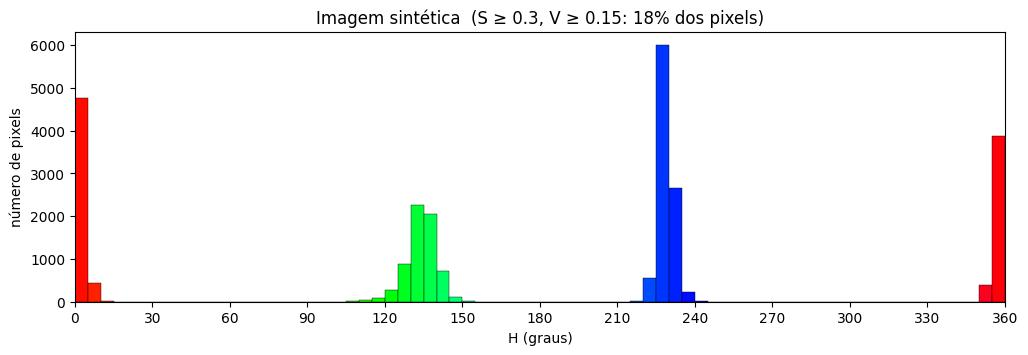

In [22]:
plt.figure(figsize=(12, 3.5))
histograma_h(hsv_sint, titulo="Imagem sintética")
plt.show()

Só 18% dos pixels passam pelos limites de saturação e valor. O fundo bege e o quadrado cinza ficam de fora, como esperado, e sobram três picos:

- vermelho, dividido em dois pedaços, um logo depois de 0° e outro logo antes de 360° (é o mesmo objeto, a roda é que dá a volta)
- verde, entre 120° e 150°
- azul, entre 220° e 240°

Cada faixa foi escolhida em volta do pico, com uma folga para os dois lados. Para o vermelho usamos de 340° a 20°, passando pelo 0°.

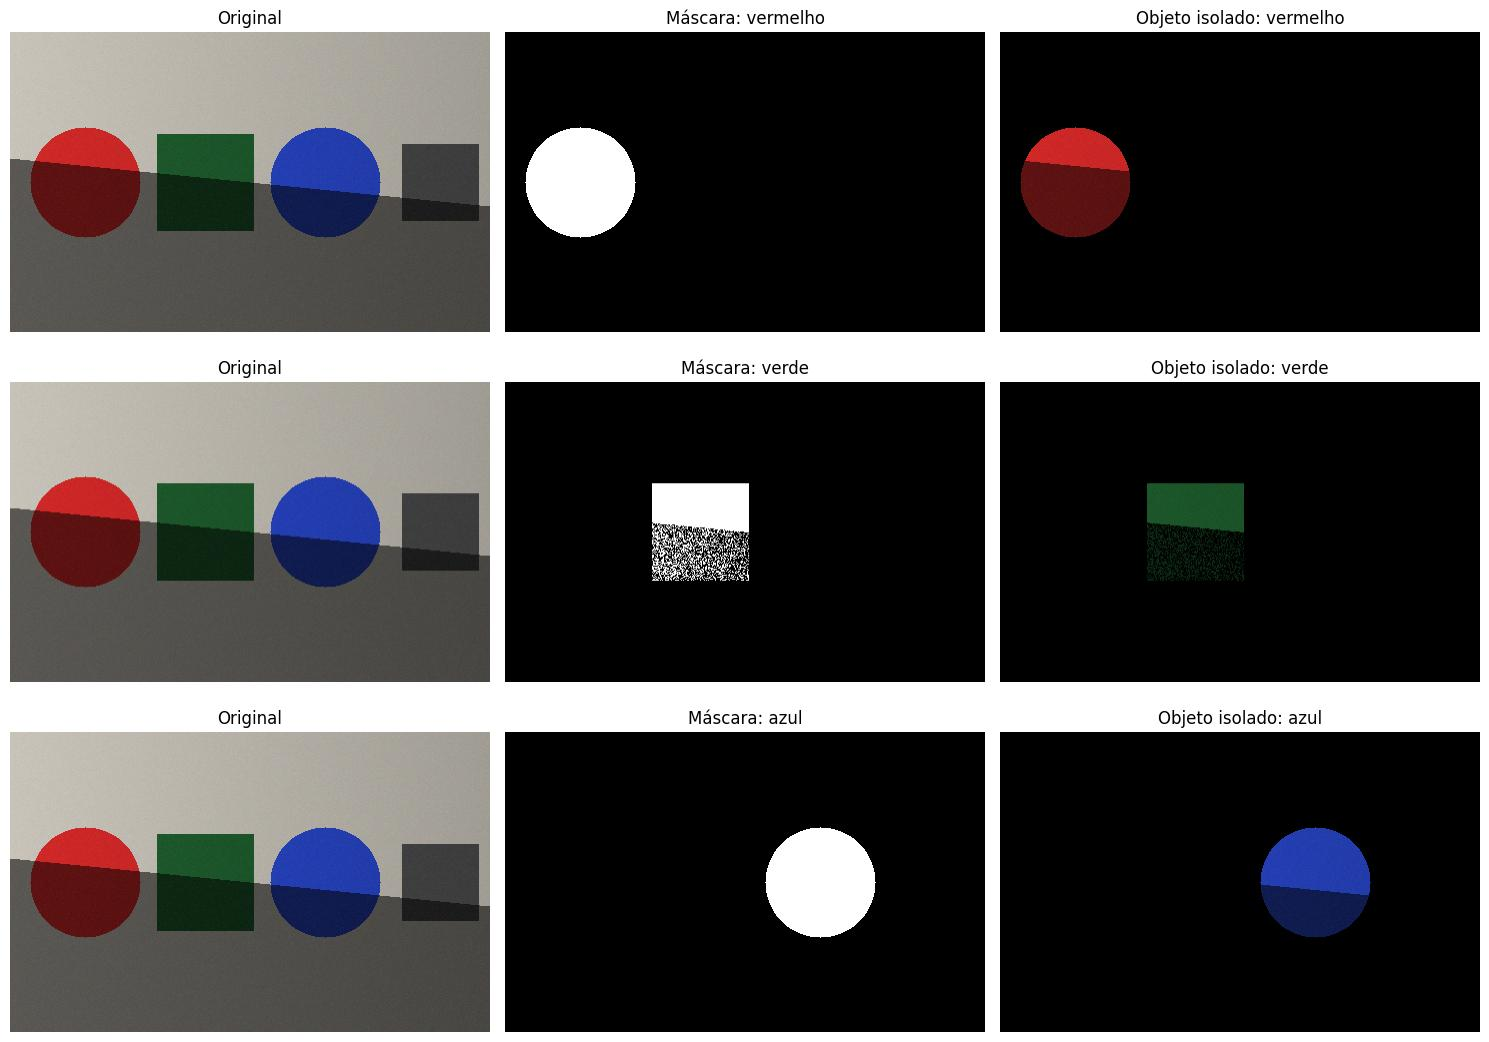

In [23]:
faixas_sint = {
    "vermelho": (340, 20),
    "verde": (110, 160),
    "azul": (210, 250),
}
mascaras_sint = {nome: segmentar_hsv(hsv_sint, h_min, h_max) for nome, (h_min, h_max) in faixas_sint.items()}
mostrar_segmentacao(img_sint, mascaras_sint)

Cada máscara pegou o objeto inteiro, inclusive a metade na sombra, e nada do fundo. Para medir isso, usamos o gabarito da seção 1 e a métrica IoU (*Intersection over Union*, interseção sobre união):

$$\text{IoU} = \frac{|\,\text{máscara} \cap \text{gabarito}\,|}{|\,\text{máscara} \cup \text{gabarito}\,|}$$

O IoU vale 1 quando a máscara é igual ao gabarito e cai tanto quando a máscara perde pixels do objeto quanto quando pega pixels de fora. Medimos também, em separado, quanto da parte sombreada de cada objeto foi encontrado.

In [24]:
def iou(mascara, gabarito):
    return (mascara & gabarito).sum() / (mascara | gabarito).sum()


print(f"{'objeto':10s} {'IoU':>6s} {'parte iluminada achada':>24s} {'parte na sombra achada':>24s}")
for nome, mascara in mascaras_sint.items():
    alvo = gabarito[nome]
    iluminada = mascara[alvo & ~sombra].mean()
    na_sombra = mascara[alvo & sombra].mean()
    print(f"{nome:10s} {iou(mascara, alvo):6.3f} {iluminada:24.1%} {na_sombra:24.1%}")

objeto        IoU   parte iluminada achada   parte na sombra achada
vermelho    1.000                   100.0%                   100.0%
verde       0.690                   100.0%                    43.3%
azul        1.000                   100.0%                   100.0%


O vermelho e o azul foram encontrados inteiros, com a parte na sombra e sem nenhum pixel a mais (IoU = 1). O verde perdeu mais da metade da parte na sombra, e na figura a metade de baixo do quadrado aparece como chuvisco.

O responsável é o $v_{min}$. O verde é a cor mais escura da cena, com $G = 92$ na parte iluminada. Na sombra ele é multiplicado por $0{,}45$ e, naquela posição, também por $\approx 0{,}92$ do gradiente de luz, o que dá $G \approx 38$ e $V \approx 38/255 \approx 0{,}149$. Esse valor cai em cima do limite $v_{min} = 0{,}15$, e o ruído joga metade dos pixels para cada lado.

Baixamos o $v_{min}$ só para o verde e medimos de novo:

In [25]:
mascara_verde = segmentar_hsv(hsv_sint, 110, 160, v_min=0.1)
mascaras_sint["verde"] = mascara_verde

alvo = gabarito["verde"]
print(f"verde com v_min = 0.1:  IoU = {iou(mascara_verde, alvo):.3f}   "
      f"parte na sombra achada = {mascara_verde[alvo & sombra].mean():.1%}   "
      f"pixels a mais (fora do gabarito) = {(mascara_verde & ~alvo).sum()}")

verde com v_min = 0.1:  IoU = 0.993   parte na sombra achada = 99.0%   pixels a mais (fora do gabarito) = 15


Com $v_{min} = 0{,}1$, o quadrado verde passa a ser encontrado quase inteiro, sombra incluída. Os poucos pixels que ainda faltam são aqueles em que o ruído deixou o verde abaixo de 0,1. Em troca entram alguns pixels a mais, da parte sombreada do quadrado cinza, onde o ruído cria saturação e, por acaso, uma matiz esverdeada.

O $v_{min}$, e o $s_{min}$ também, tem esse custo. Alto demais, perde as partes escuras do objeto; baixo demais, deixa entrar pixels sem cor de verdade. O valor certo muda de imagem para imagem, conforme o quanto o objeto escurece na sombra e o quanto de ruído a foto tem.

### Exemplo 2: carretéis de linha

Agora uma foto: cinco carretéis de madeira sobre fundo branco, com linhas verde-escura, amarela, azul-marinho, rosa-clara e vermelho-alaranjada.

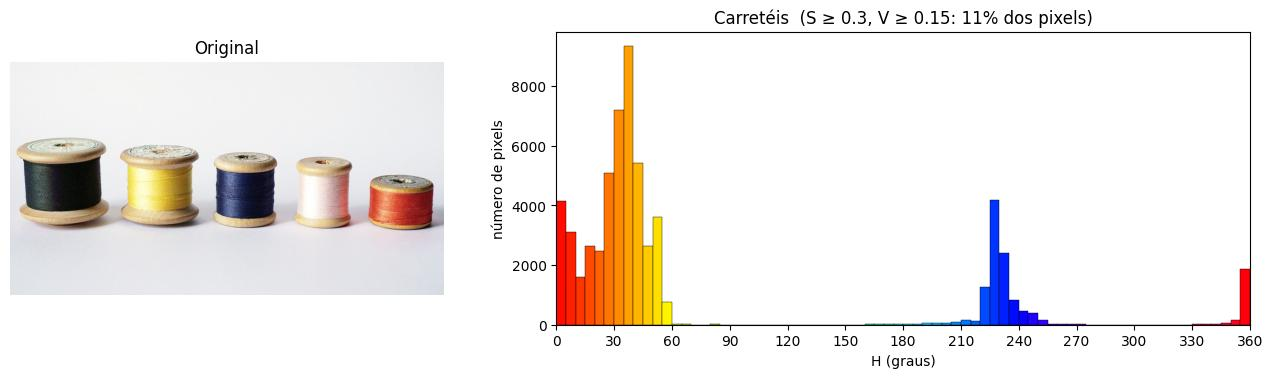

In [26]:
img_carreteis = carregar("imagens/objetos_coloridos.jpg")
hsv_carreteis = rgb_para_hsv(img_carreteis)

fig, eixos = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
eixos[0].imshow(img_carreteis)
eixos[0].axis("off")
eixos[0].set_title("Original")
histograma_h(hsv_carreteis, eixo=eixos[1], titulo="Carretéis")
plt.show()

Desta vez só 11% dos pixels passam pelos limites. O fundo branco, a linha rosa-clara e a linha verde-escura ficam de fora (o motivo aparece mais abaixo). Os picos são:

- vermelho-alaranjado, de novo dividido entre o começo (0° a 20°) e o fim (355° a 360°) da roda
- um pico laranja muito alto, entre 25° e 45°, que não vem de nenhuma linha. É a madeira dos carretéis: madeira clara é um laranja pouco saturado, e com $s_{min} = 0{,}3$ boa parte dela passa.
- amarelo, entre 45° e 60°, colado no pico da madeira
- azul, entre 215° e 250°

As faixas foram escolhidas para fugir do pico da madeira: o vermelho vai só até 20° e o amarelo começa em 45°. Subimos o $s_{min}$ do vermelho para 0,5 e o do amarelo para 0,35, para cortar a madeira mais saturada. No azul, que é uma linha escura, o $v_{min}$ desceu para 0,1, pelo mesmo motivo do quadrado verde.

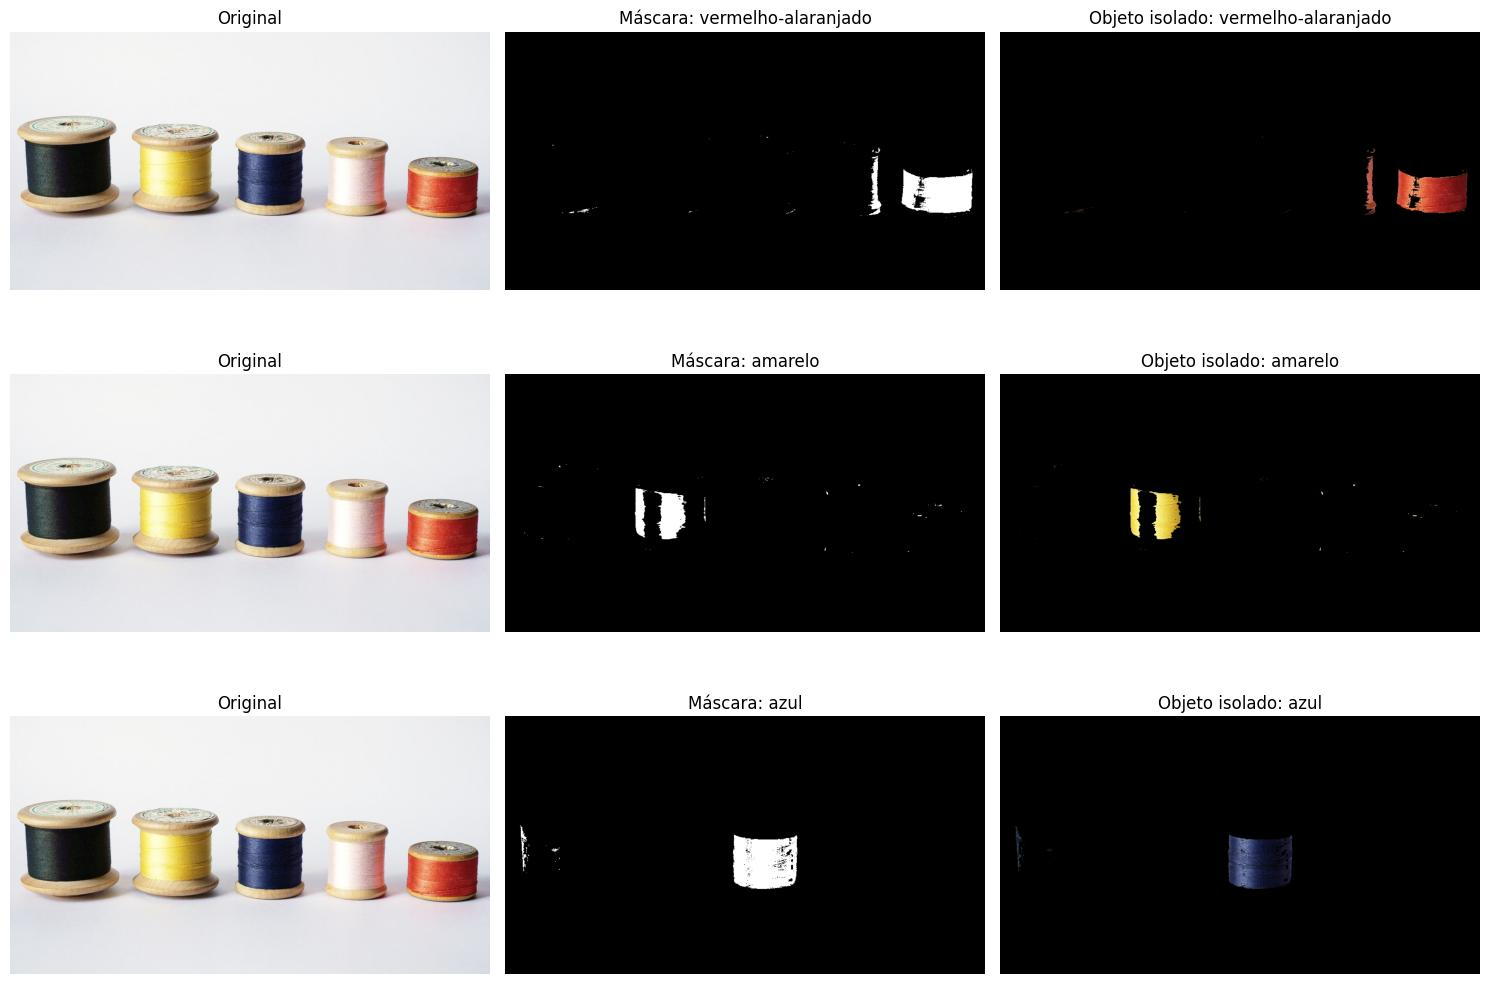

In [27]:
# nome: (h_min, h_max, s_min, v_min)
faixas_carreteis = {
    "vermelho-alaranjado": (345, 20, 0.5, 0.15),
    "amarelo": (45, 65, 0.35, 0.15),
    "azul": (210, 250, 0.3, 0.1),
}
mascaras_carreteis = {nome: segmentar_hsv(hsv_carreteis, *limites)
                      for nome, limites in faixas_carreteis.items()}
mostrar_segmentacao(img_carreteis, mascaras_carreteis)

Cada máscara pegou a linha certa e deixou de fora a madeira e o fundo. Numa foto, porém, o resultado não sai tão limpo quanto na imagem sintética:

- Aparecem buracos dentro das linhas, e na amarela some uma faixa vertical inteira. São os brilhos do fio: onde a luz reflete direto para a câmera, a cor fica quase branca e a saturação cai abaixo do $s_{min}$.
- A máscara do vermelho pega uma faixa estreita na borda do carretel rosa. Ali a linha rosa fica na penumbra, e a cor dela, um vermelho bem claro, fica saturada o bastante para passar.
- A máscara do azul pega um pedaço da borda esquerda do carretel verde-escuro, onde a linha escura tem um leve tom azulado.

Para entender por que duas linhas sumiram e de onde veio o pico da madeira, medimos H, S e V em pequenas regiões de cada carretel:

In [28]:
# Valores médios de H, S e V em pequenas regiões (10 x 10 pixels) de cada carretel
regioes = {
    "linha verde-escura": (287, 120),
    "linha amarela": (287, 340),
    "linha azul": (287, 540),
    "linha rosa-clara": (287, 720),
    "linha vermelho-alaranjada": (330, 900),
    "madeira do carretel": (373, 120),
}
print(f"{'região':27s} {'H (°)':>7s} {'S':>6s} {'V':>6s}")
for nome, (lin, col) in regioes.items():
    h, s, v = hsv_carreteis[lin - 5:lin + 5, col - 5:col + 5].reshape(-1, 3).T
    print(f"{nome:27s} {media_circular(h):7.1f} {s.mean():6.2f} {v.mean():6.2f}")

região                        H (°)      S      V
linha verde-escura            352.3   0.19   0.08
linha amarela                  52.4   0.60   0.95
linha azul                    229.4   0.67   0.25
linha rosa-clara               20.9   0.09   0.95
linha vermelho-alaranjada       6.9   0.77   0.80
madeira do carretel            28.0   0.43   0.58


- Linha verde-escura: $V = 0{,}08$ e $S = 0{,}19$. A linha é quase preta e falha nos dois limites. A matiz medida foi 352°, um "vermelho" numa linha verde. Com o pixel escuro e pouco saturado, quem decide o H é o ruído, e o $s_{min}$ e o $v_{min}$ estão na regra para barrar esse caso.
- Linha rosa-clara: $S = 0{,}09$. Rosa-claro é vermelho com muito branco, e no HSV fica quase em cima do eixo dos cinzas. Só entraria com um $s_{min}$ muito baixo, e aí o fundo branco e a madeira entrariam junto.
- Madeira: $H = 28°$ e $S = 0{,}43$, um laranja de saturação média, entre a linha vermelho-alaranjada (7°) e a amarela (52°). É ela que forma o pico alto do histograma.

A segmentação por matiz separa bem cores fortes e diferentes entre si, e tem dificuldade com cores muito escuras, muito claras ou pálidas. A seção 7 volta a esse ponto.

### Exemplo 3: parede amarela com sombra

O último exemplo é o caso que motivou o tutorial: um objeto de uma cor só, metade no sol e metade na sombra. A foto é de uma parede amarela com a sombra de uma marquise rosa.

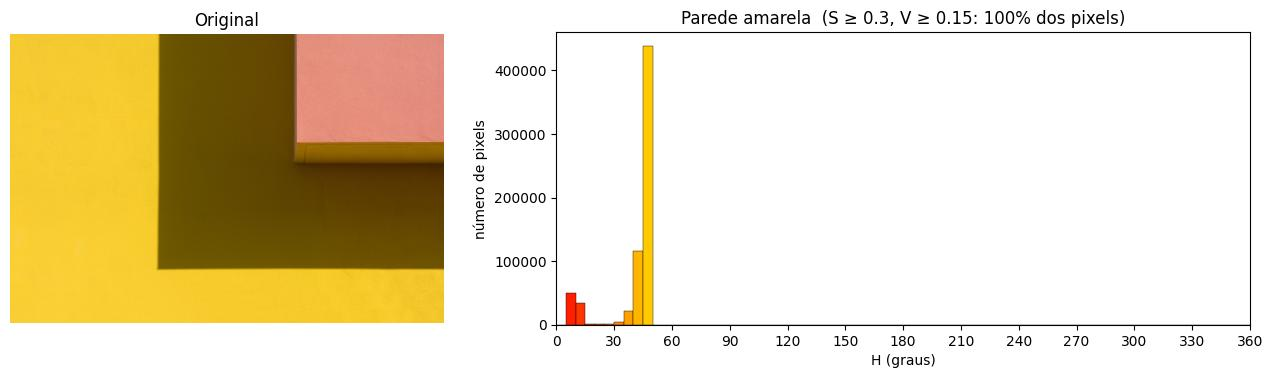

In [29]:
img_parede = carregar("imagens/sombra_amarela.jpg")
hsv_parede = rgb_para_hsv(img_parede)

fig, eixos = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
eixos[0].imshow(img_parede)
eixos[0].axis("off")
eixos[0].set_title("Original")
histograma_h(hsv_parede, eixo=eixos[1], titulo="Parede amarela")
plt.show()

Quase todos os pixels da foto são saturados, e o histograma tem só dois picos: o amarelo da parede, entre 35° e 50°, e o vermelho-alaranjado da marquise rosa, entre 5° e 15°. O pico amarelo é um só, porque a parede no sol e a parede na sombra caem na mesma faixa de matiz. Se a sombra mudasse a matiz, haveria dois picos amarelos separados. Usamos a faixa de 35° a 60°.

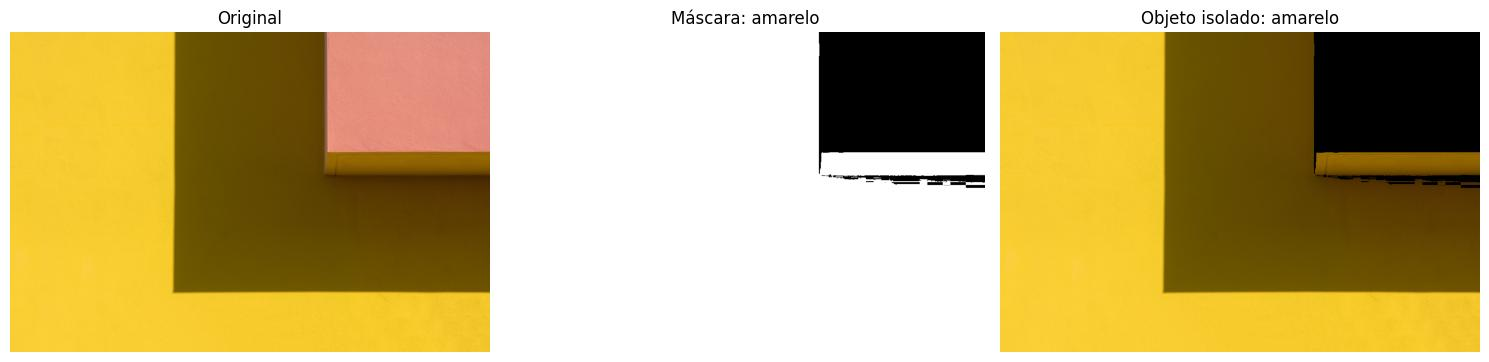

parede no sol     RGB = (249.1, 206.1,  50.1)   H =  47.0°  S = 0.80  V = 0.98
parede na sombra  RGB = ( 95.2,  71.1,   0.8)   H =  44.7°  S = 0.99  V = 0.37


In [30]:
mascara_parede = segmentar_hsv(hsv_parede, 35, 60)
mostrar_segmentacao(img_parede, {"amarelo": mascara_parede})

for nome, (lin, col) in {"parede no sol": (450, 150), "parede na sombra": (400, 600)}.items():
    rgb = img_parede[lin - 20:lin + 20, col - 20:col + 20].reshape(-1, 3).mean(axis=0)
    h, s, v = hsv_parede[lin - 20:lin + 20, col - 20:col + 20].reshape(-1, 3).T
    print(f"{nome:17s} RGB = ({rgb[0]:5.1f}, {rgb[1]:5.1f}, {rgb[2]:5.1f})   "
          f"H = {media_circular(h):5.1f}°  S = {s.mean():.2f}  V = {v.mean():.2f}")

A máscara pegou a parede inteira, parte no sol e parte na sombra, e deixou de fora só a marquise. As medições confirmam numa foto o que a teoria da seção 3 previa:

- Em RGB, a sombra derrubou os três canais. O R caiu de cerca de 249 para 95, o G de 206 para 71, e o B ficou praticamente em zero.
- Em HSV, a matiz quase não mudou (de cerca de 47° para 45°), e quem caiu foi o V (de 0,98 para 0,37). O S até subiu um pouco, porque na sombra o B foi a zero e a cor ficou mais pura.

Faltam só os pixels de uma faixa estreita logo abaixo da marquise, onde a sombra é tão forte que o V fica abaixo do $v_{min}$.

A próxima seção tenta isolar os mesmos objetos direto em RGB.

<a id="secao6"></a>

## 6. Comparação: a mesma segmentação em RGB

Na Entrega 1 nos comprometemos a mostrar por que o HSV funciona melhor que o RGB para segmentar por cor. Nesta seção repetimos a tarefa em RGB, com as mesmas imagens, e comparamos os números.

### Teoria: segmentação por caixa em RGB

O jeito mais direto de segmentar por cor em RGB é dar um limite mínimo e um máximo para cada canal:

$$r_{min} \le R \le r_{max} \quad\text{e}\quad g_{min} \le G \le g_{max} \quad\text{e}\quad b_{min} \le B \le b_{max}$$

No cubo RGB, essa regra é uma caixa com os lados paralelos aos eixos, e o pixel é objeto se cair dentro dela.

Para a comparação ser justa com o RGB, escolhemos os limites como alguém faria na prática: pegamos uma amostra de pixels da parte bem iluminada do objeto e medimos a faixa de cada canal. Usamos os percentis 1 e 99 no lugar do mínimo e do máximo, para que alguns pixels de ruído não estiquem a caixa, e damos uma folga de 20 níveis para cada lado.

### Prática: as funções

In [31]:
def segmentar_rgb(img, minimo, maximo):
    """Máscara dos pixels com cada canal entre minimo[c] e maximo[c] (uma caixa no cubo RGB)."""
    return np.all((img >= minimo) & (img <= maximo), axis=-1)


def caixa_da_amostra(amostra, folga=20):
    """Limites (mínimo, máximo) de cada canal: percentis 1 e 99 da amostra, com folga."""
    minimo = np.percentile(amostra, 1, axis=0) - folga
    maximo = np.percentile(amostra, 99, axis=0) + folga
    return np.clip(minimo, 0, 255), np.clip(maximo, 0, 255)


def mostrar_comparacao(img, mascaras):
    """Original seguida de uma máscara por coluna."""
    fig, eixos = plt.subplots(1, len(mascaras) + 1, figsize=(4.2 * (len(mascaras) + 1), 4))
    eixos[0].imshow(img)
    eixos[0].set_title("Original")
    for eixo, (nome, mascara) in zip(eixos[1:], mascaras.items()):
        eixo.imshow(mascara, cmap="gray")
        eixo.set_title(nome)
    for eixo in eixos:
        eixo.axis("off")
    plt.tight_layout()
    plt.show()

### Exemplo 1: imagem sintética

A amostra de cada objeto é a parte iluminada dele, tirada do gabarito. A máscara HSV é a da seção 5, com $v_{min} = 0{,}1$ no verde.

objeto    caixa RGB (mín → máx)               IoU RGB  IoU HSV  sombra RGB  sombra HSV
vermelho  [175, 12, 12] → [231, 66, 66]         0.313    1.000        0.0%      100.0%
verde     [1, 57, 14] → [55, 112, 68]           0.449    0.993        0.0%       99.0%
azul      [8, 33, 145] → [62, 88, 202]          0.587    1.000        0.0%      100.0%


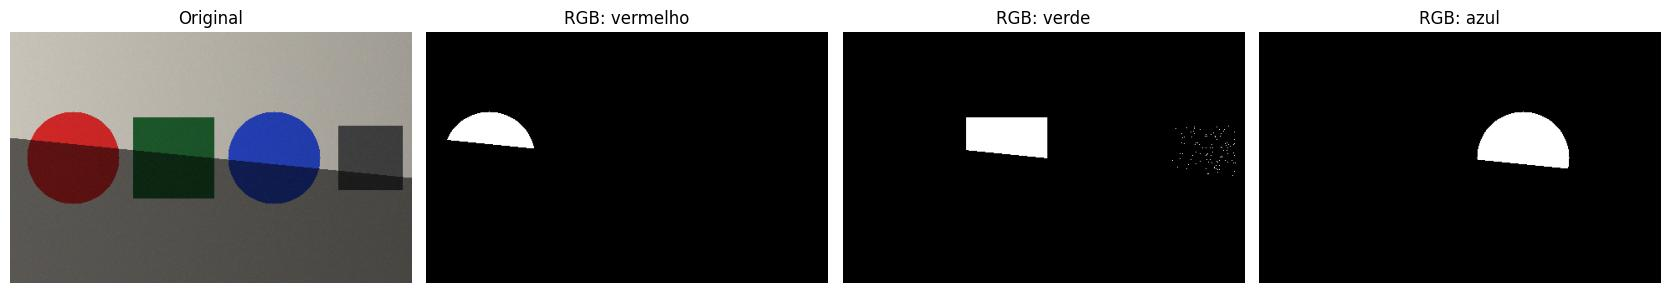

In [32]:
caixas_sint = {}
mascaras_rgb_sint = {}
for nome in ["vermelho", "verde", "azul"]:
    amostra = img_sint[gabarito[nome] & ~sombra]
    caixas_sint[nome] = caixa_da_amostra(amostra)
    mascaras_rgb_sint[nome] = segmentar_rgb(img_sint, *caixas_sint[nome])

print(f"{'objeto':9s} {'caixa RGB (mín → máx)':34s} {'IoU RGB':>8s} {'IoU HSV':>8s} {'sombra RGB':>11s} {'sombra HSV':>11s}")
for nome in ["vermelho", "verde", "azul"]:
    alvo = gabarito[nome]
    m_rgb, m_hsv = mascaras_rgb_sint[nome], mascaras_sint[nome]
    minimo, maximo = caixas_sint[nome]
    texto_caixa = f"{minimo.round().astype(int).tolist()} → {maximo.round().astype(int).tolist()}"
    print(f"{nome:9s} {texto_caixa:34s} {iou(m_rgb, alvo):8.3f} {iou(m_hsv, alvo):8.3f} "
          f"{m_rgb[alvo & sombra].mean():11.1%} {m_hsv[alvo & sombra].mean():11.1%}")

mostrar_comparacao(img_sint, {"RGB: vermelho": mascaras_rgb_sint["vermelho"],
                              "RGB: verde": mascaras_rgb_sint["verde"],
                              "RGB: azul": mascaras_rgb_sint["azul"]})

Cada caixa foi montada com a parte iluminada do objeto, e só a parte iluminada ela encontra: 0% da parte na sombra nos três objetos. O IoU fica entre 0,31 e 0,59, contra 0,99 a 1,00 do HSV nas mesmas imagens.

Na caixa do vermelho, o R vai de 175 a 231. Na sombra, o R do círculo cai para cerca de 90 (tabela da seção 2), bem abaixo de 175.

objeto       IoU  sombra achada  pixels a mais
vermelho   0.468         100.0%          10775
verde      0.854         100.0%           1604
azul       0.417         100.0%          13270


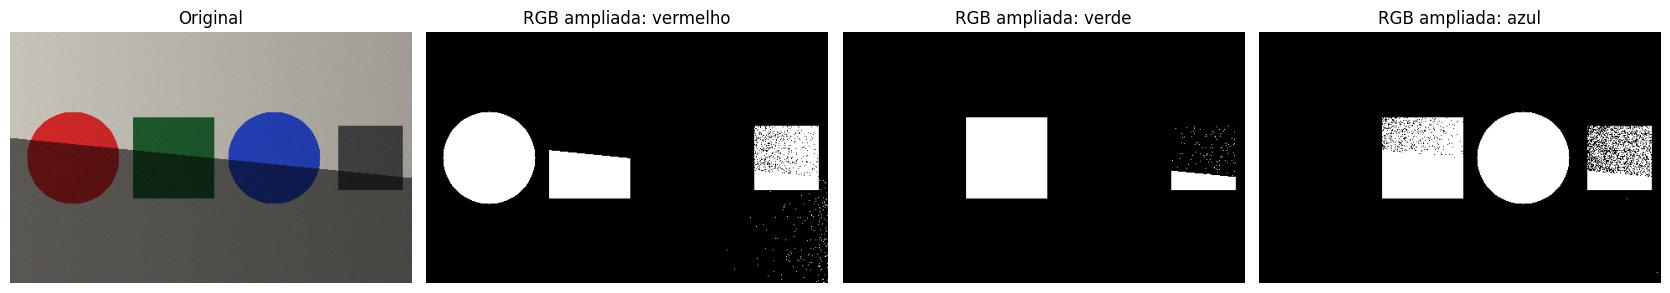

In [33]:
mascaras_rgb_ampliada = {}
print(f"{'objeto':9s} {'IoU':>6s} {'sombra achada':>14s} {'pixels a mais':>14s}")
for nome in ["vermelho", "verde", "azul"]:
    minimo, maximo = caixas_sint[nome]
    mascaras_rgb_ampliada[nome] = segmentar_rgb(img_sint, np.zeros(3), maximo)
    m, alvo = mascaras_rgb_ampliada[nome], gabarito[nome]
    print(f"{nome:9s} {iou(m, alvo):6.3f} {m[alvo & sombra].mean():14.1%} {(m & ~alvo).sum():14d}")

mostrar_comparacao(img_sint, {"RGB ampliada: vermelho": mascaras_rgb_ampliada["vermelho"],
                              "RGB ampliada: verde": mascaras_rgb_ampliada["verde"],
                              "RGB ampliada: azul": mascaras_rgb_ampliada["azul"]})

Uma tentativa de corrigir a caixa é baixar todos os mínimos para zero, para a parte escura do objeto também caber. Testamos isso mantendo os máximos e trocando os mínimos por 0:

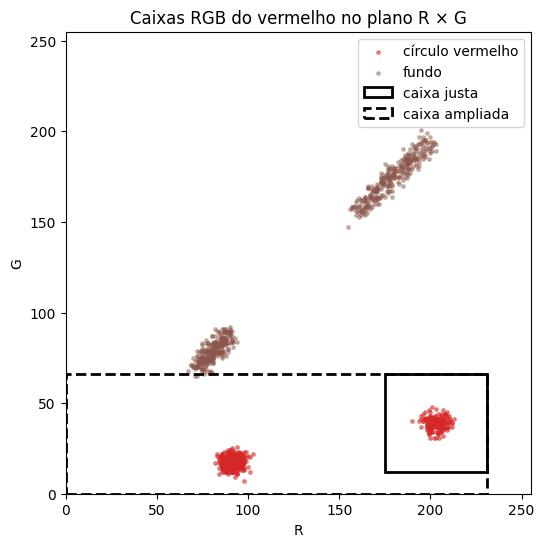

In [34]:
pixels_vermelho = img_sint[gabarito["vermelho"]]
pixels_fundo = img_sint[~np.any(list(gabarito.values()), axis=0)]
amostra_v = pixels_vermelho[rng.choice(len(pixels_vermelho), 600, replace=False)]
amostra_f = pixels_fundo[rng.choice(len(pixels_fundo), 600, replace=False)]

fig, eixo = plt.subplots(figsize=(6, 6))
eixo.scatter(amostra_v[:, 0], amostra_v[:, 1], s=6, color="tab:red", alpha=0.5, label="círculo vermelho")
eixo.scatter(amostra_f[:, 0], amostra_f[:, 1], s=6, color="tab:brown", alpha=0.4, label="fundo")
minimo, maximo = caixas_sint["vermelho"]
eixo.add_patch(plt.Rectangle(minimo[:2], *(maximo[:2] - minimo[:2]), fill=False, color="black",
                             linewidth=2, label="caixa justa"))
eixo.add_patch(plt.Rectangle((0, 0), *maximo[:2], fill=False, color="black", linestyle="--",
                             linewidth=2, label="caixa ampliada"))
eixo.set_xlim(0, 255)
eixo.set_ylim(0, 255)
eixo.set_xlabel("R")
eixo.set_ylabel("G")
eixo.set_title("Caixas RGB do vermelho no plano R × G")
eixo.legend()
plt.show()

A sombra agora entra (100% nos três objetos), mas a máscara passa a pegar milhares de pixels de fora do objeto. A caixa ampliada do vermelho pega a parte sombreada do quadrado verde, o quadrado cinza e pontos do fundo na sombra, e a do azul pega partes do verde e do cinza. O IoU continua baixo, entre 0,42 e 0,85.

O gráfico abaixo mostra o motivo, no mesmo plano R × G da seção 2. O vermelho forma dois grupos, o iluminado perto de (200, 40) e o da sombra perto de (90, 20). A caixa justa (linha cheia) cerca só o grupo iluminado. Para cercar os dois, a caixa tem que ir até a origem (linha tracejada), e com isso engole toda a região escura do cubo, onde ficam também as sombras das outras cores.

### Exemplo 2: parede amarela

A amostra é um retângulo da parede no sol, do lado esquerdo da foto. Para medir o resultado, usamos dois retângulos que sabemos ser só parede, um no sol e outro na sombra.

Caixa RGB: [224. 181.  25.] → [255. 230.  80.]


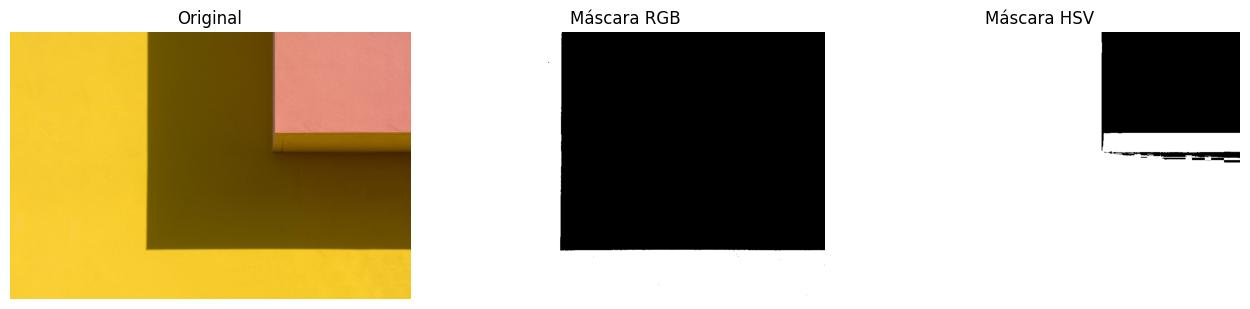

              parede no sol  parede na sombra
RGB                  100.0%              0.0%
HSV                  100.0%            100.0%


In [35]:
zona_sol = (slice(400, 600), slice(30, 250))
zona_sombra = (slice(330, 500), slice(400, 900))

caixa_parede = caixa_da_amostra(img_parede[zona_sol].reshape(-1, 3))
mascara_parede_rgb = segmentar_rgb(img_parede, *caixa_parede)
print("Caixa RGB:", caixa_parede[0].round(), "→", caixa_parede[1].round())

mostrar_comparacao(img_parede, {"Máscara RGB": mascara_parede_rgb, "Máscara HSV": mascara_parede})

print(f"{'':12s} {'parede no sol':>14s} {'parede na sombra':>17s}")
for nome, m in [("RGB", mascara_parede_rgb), ("HSV", mascara_parede)]:
    print(f"{nome:12s} {m[zona_sol].mean():14.1%} {m[zona_sombra].mean():17.1%}")

Na parede amarela o resultado se repete: a caixa RGB encontra 100% da parede no sol e 0% da parede na sombra. Na sombra, o RGB da parede fica em torno de (95, 71, 1), e a caixa exige R ≥ 224 e G ≥ 181. O HSV encontra 100% das duas partes com uma única faixa de matiz.

### Experimento: diminuindo a luz da foto inteira

Uma sombra é uma região com menos luz. A foto inteira fica nessa situação quando a cena é fotografada mais tarde ou com o céu nublado. Simulamos isso multiplicando a imagem toda por um fator $k$, como a sombra faz, e segmentamos com os mesmos limites de antes. Depois comparamos cada máscara com a máscara do mesmo método na foto original (IoU = 1 quer dizer que nada mudou).

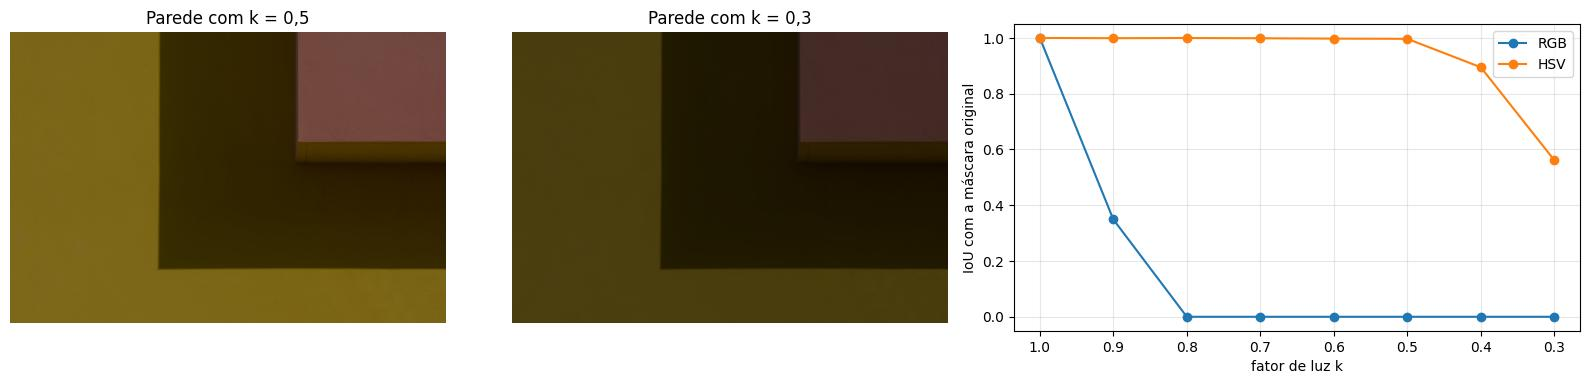

    k  IoU RGB  IoU HSV
  1.0    1.000    1.000
  0.9    0.349    0.999
  0.8    0.000    1.000
  0.7    0.000    0.999
  0.6    0.000    0.998
  0.5    0.000    0.997
  0.4    0.000    0.895
  0.3    0.000    0.562


In [36]:
def escurecer(img, k):
    return np.clip(np.round(img * k), 0, 255).astype(np.uint8)


fatores = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3]
iou_rgb, iou_hsv = [], []
for k in fatores:
    escura = escurecer(img_parede, k)
    iou_rgb.append(iou(segmentar_rgb(escura, *caixa_parede), mascara_parede_rgb))
    iou_hsv.append(iou(segmentar_hsv(rgb_para_hsv(escura), 35, 60), mascara_parede))

fig, eixos = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.3]})
eixos[0].imshow(escurecer(img_parede, 0.5))
eixos[0].set_title("Parede com k = 0,5")
eixos[0].axis("off")
eixos[1].imshow(escurecer(img_parede, 0.3))
eixos[1].set_title("Parede com k = 0,3")
eixos[1].axis("off")
eixos[2].plot(fatores, iou_rgb, "o-", label="RGB")
eixos[2].plot(fatores, iou_hsv, "o-", label="HSV")
eixos[2].invert_xaxis()
eixos[2].set_xlabel("fator de luz k")
eixos[2].set_ylabel("IoU com a máscara original")
eixos[2].set_ylim(-0.05, 1.05)
eixos[2].legend()
eixos[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'k':>5s} {'IoU RGB':>8s} {'IoU HSV':>8s}")
for k, a, b in zip(fatores, iou_rgb, iou_hsv):
    print(f"{k:5.1f} {a:8.3f} {b:8.3f}")

O RGB falha quase de imediato. Com 10% a menos de luz ($k = 0{,}9$), a máscara já perde a maior parte da parede, e a partir de $k = 0{,}8$ fica vazia (IoU = 0). O limite mínimo da caixa (R ≥ 224) foi medido numa parede com R ≈ 249, e qualquer redução de luz põe o R abaixo dele.

O HSV fica praticamente igual (IoU ≥ 0,997) até $k = 0{,}5$, com metade da luz. Ele só começa a perder pixels em $k = 0{,}4$ e $k = 0{,}3$, de novo por causa do $v_{min}$: a parte que já estava na sombra tinha $V \approx 0{,}37$, e $0{,}37 \times 0{,}4 \approx 0{,}148$ fica abaixo de $v_{min} = 0{,}15$. A matiz continua certa, mas o pixel ficou escuro demais para a regra aceitar.

### Exemplo 3: parede vermelha com sombra de grade

Esta cena é mais difícil: uma parede vermelha com a sombra de uma grade e de um poste, e um chão de terra embaixo. O chão é marrom, e marrom é um laranja-avermelhado escuro, parecido com a parede na sombra.

Testamos duas caixas RGB, uma com amostra só da parte no sol e outra, maior, com amostra do sol e da sombra, para tentar pegar a parede inteira. No HSV usamos a faixa do vermelho de 345° a 20°.

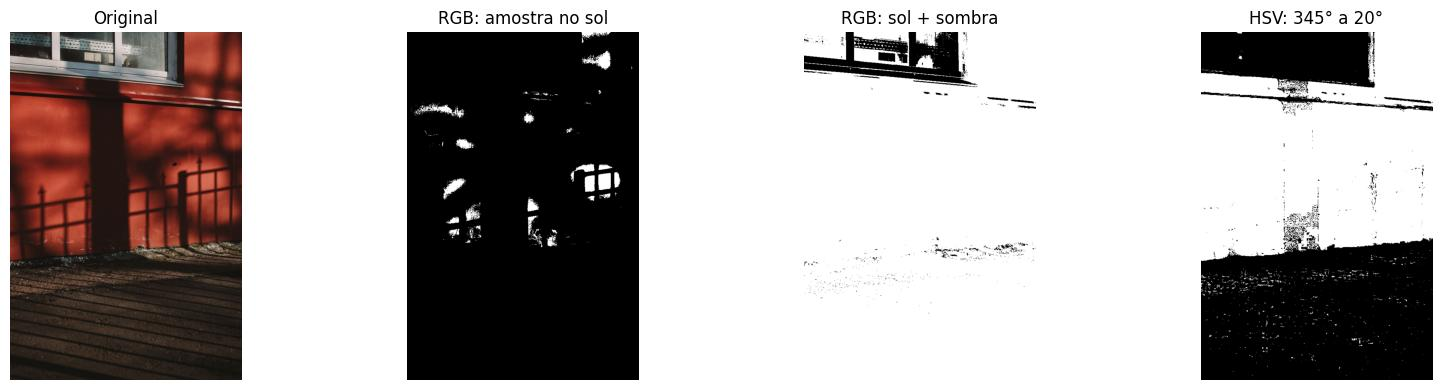

máscara                 parede marcada  chão marcado
RGB: amostra no sol               5.3%          0.0%
RGB: sol + sombra                99.8%         99.9%
HSV: 345° a 20°                  97.5%          1.3%


In [37]:
img_vermelha = carregar("imagens/sombra_vermelha.jpg")
hsv_vermelha = rgb_para_hsv(img_vermelha)

amostra_sol = img_vermelha[420:440, 560:580].reshape(-1, 3)
amostra_sombra = img_vermelha[300:400, 260:310].reshape(-1, 3)
caixa_sol = caixa_da_amostra(amostra_sol)
caixa_sol_e_sombra = caixa_da_amostra(np.vstack([amostra_sol, amostra_sombra]))

mascaras_vermelha = {
    "RGB: amostra no sol": segmentar_rgb(img_vermelha, *caixa_sol),
    "RGB: sol + sombra": segmentar_rgb(img_vermelha, *caixa_sol_e_sombra),
    "HSV: 345° a 20°": segmentar_hsv(hsv_vermelha, 345, 20, s_min=0.4, v_min=0.1),
}
mostrar_comparacao(img_vermelha, mascaras_vermelha)

zona_parede = (slice(200, 600), slice(None))
zona_chao = (slice(700, None), slice(None))
print(f"{'máscara':22s} {'parede marcada':>15s} {'chão marcado':>13s}")
for nome, m in mascaras_vermelha.items():
    print(f"{nome:22s} {m[zona_parede].mean():15.1%} {m[zona_chao].mean():13.1%}")

As máscaras mostram as duas formas de o RGB falhar:

- A caixa com amostra no sol pega só 5% da parede. A luz nessa parede varia (sombra da grade, sombra do poste, manchas de luz mais forte), e só as manchas mais iluminadas cabem na caixa.
- A caixa com sol e sombra pega quase toda a parede (99,8%), mas também quase todo o chão (99,9%) e parte da janela. Para caber o vermelho escuro da sombra, a caixa cresceu tanto que o marrom do chão também cabe.
- O HSV pega 97,5% da parede e só 1,3% do chão. O chão tem matiz em torno de 25° a 30°, um laranja escuro fora da faixa de 345° a 20°, e saturação mais baixa. A parede na sombra continua com matiz por volta de 10°, igual à parte no sol.

### Resumo da comparação

| Teste | RGB (caixa) | HSV (faixa de matiz) |
|---|---|---|
| Sintética, caixa justa (IoU) | 0,31 a 0,59, perde toda a sombra | 0,99 a 1,00 |
| Sintética, caixa ampliada (IoU) | 0,42 a 0,85, pega outros objetos | 0,99 a 1,00 |
| Parede amarela: sombra encontrada | 0% | 100% |
| Foto com metade da luz ($k = 0{,}5$) | máscara vazia | IoU = 0,997 |
| Parede vermelha: parede / chão marcados | 5% / 0% (caixa justa) ou 99,8% / 99,9% (caixa grande) | 97,5% / 1,3% |

Em todos os testes o motivo foi o mesmo, e é o que as seções 2 e 3 previam. Em RGB, cor e brilho estão misturados nos três canais, e uma sombra muda os três de uma vez. Em HSV o brilho fica isolado no V, e a matiz, que usamos para decidir a cor, quase não muda.

O HSV também falha em alguns casos, que estão na próxima seção.

<a id="secao7"></a>

## 7. Limitações

A segmentação por matiz resolveu o problema da sombra, mas tem limites. Alguns já apareceram nas seções anteriores, e aqui mostramos mais dois com fotos.

### Reflexos

Um objeto brilhante, como uma maçã, reflete parte da luz direto para a câmera. Nesses pontos o pixel recebe a cor da luz, quase branca, no lugar da cor do objeto. No HSV, um pixel quase branco tem saturação baixa, e o $s_{min}$ o descarta.

A foto abaixo é de uma maçã vermelha sobre fundo laranja.

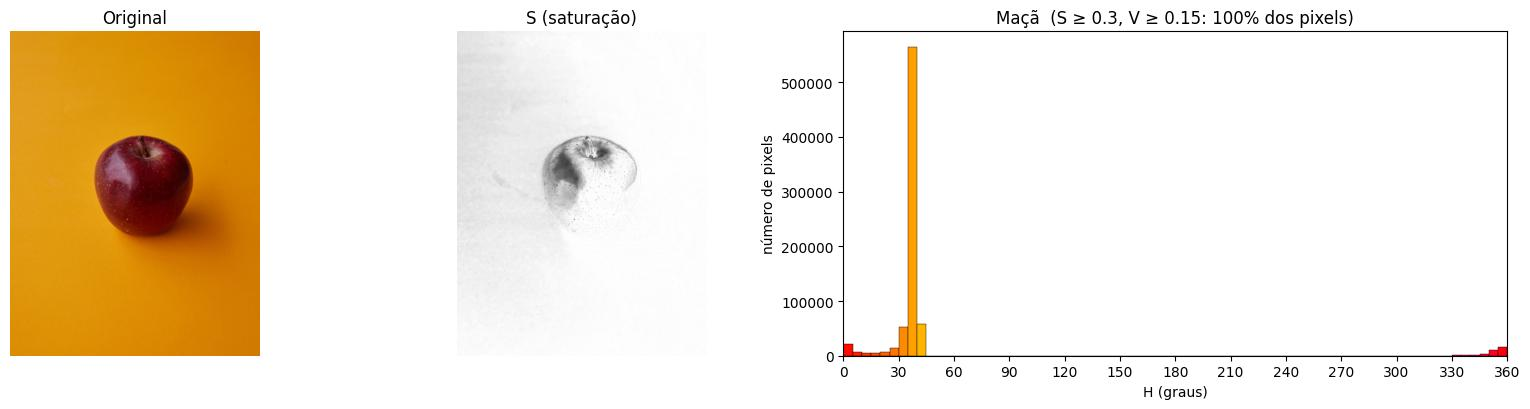

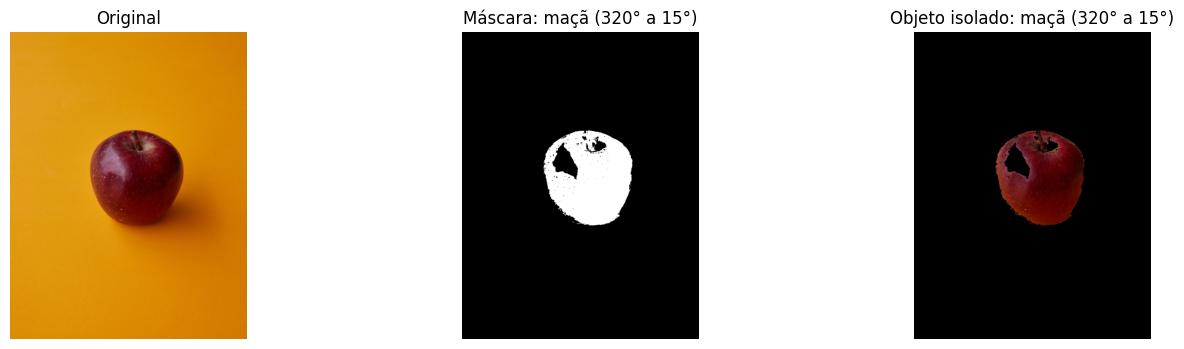

região                   H (°)      S      V
maçã                     359.7   0.98   0.25
reflexo na maçã          340.1   0.46   0.56
fundo laranja             39.3   0.90   0.88


In [38]:
img_maca = carregar("imagens/maca_fundo_laranja.jpg")
hsv_maca = rgb_para_hsv(img_maca)

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.8]})
eixos[0].imshow(img_maca)
eixos[0].set_title("Original")
eixos[1].imshow(hsv_maca[..., 1], cmap="gray", vmin=0, vmax=1)
eixos[1].set_title("S (saturação)")
for eixo in eixos[:2]:
    eixo.axis("off")
histograma_h(hsv_maca, eixo=eixos[2], titulo="Maçã")
plt.tight_layout()
plt.show()

mascara_maca = segmentar_hsv(hsv_maca, 320, 15, s_min=0.5, v_min=0.1)
mostrar_segmentacao(img_maca, {"maçã (320° a 15°)": mascara_maca})

print(f"{'região':22s} {'H (°)':>7s} {'S':>6s} {'V':>6s}")
for nome, (lin, col) in {"maçã": (520, 450), "reflexo na maçã": (420, 300), "fundo laranja": (150, 150)}.items():
    h, s, v = hsv_maca[lin - 8:lin + 8, col - 8:col + 8].reshape(-1, 3).T
    print(f"{nome:22s} {media_circular(h):7.1f} {s.mean():6.2f} {v.mean():6.2f}")

No geral a segmentação funciona. O fundo laranja fica em volta de 39° e a maçã entre 330° e 360° (um vermelho puxado para o magenta), então as duas cores ficam bem separadas no histograma. A sombra que a maçã projeta no fundo, com matiz por volta de 25°, também ficou de fora.

A máscara, porém, tem um buraco grande no lado esquerdo da maçã, onde fica o reflexo da luz. Na imagem do S o reflexo é uma mancha mais escura: ali a saturação cai para cerca de 0,46, contra 0,98 no resto da maçã, abaixo do $s_{min} = 0{,}5$. Baixar o $s_{min}$ até o reflexo entrar não resolve, porque o centro do reflexo é quase branco e não tem matiz. Nesse ponto a foto não guarda a cor da maçã.

### Cores pálidas e cores que só diferem no brilho

A segmentação por matiz supõe que os objetos têm matizes diferentes, e a foto abaixo não atende a isso. São pastilhas e placas em tons pastel de pêssego, rosa, bege e marrom, e para o HSV todos esses tons são variações do mesmo laranja-avermelhado. De um objeto para outro mudam a saturação e o brilho, enquanto a matiz fica parecida.

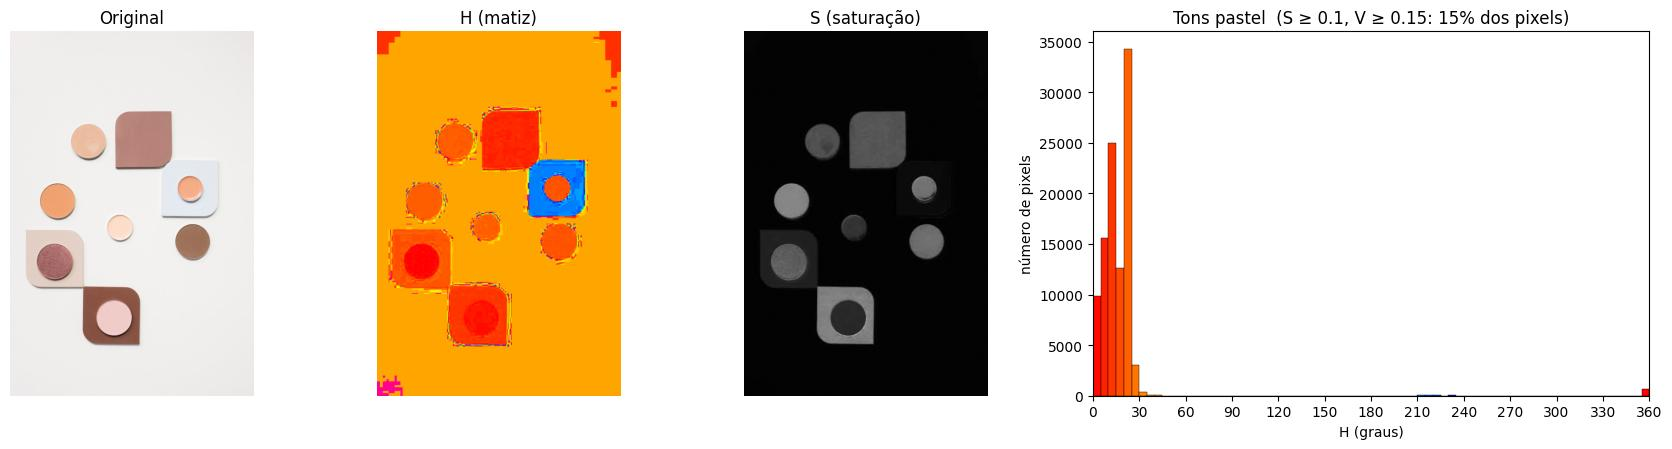

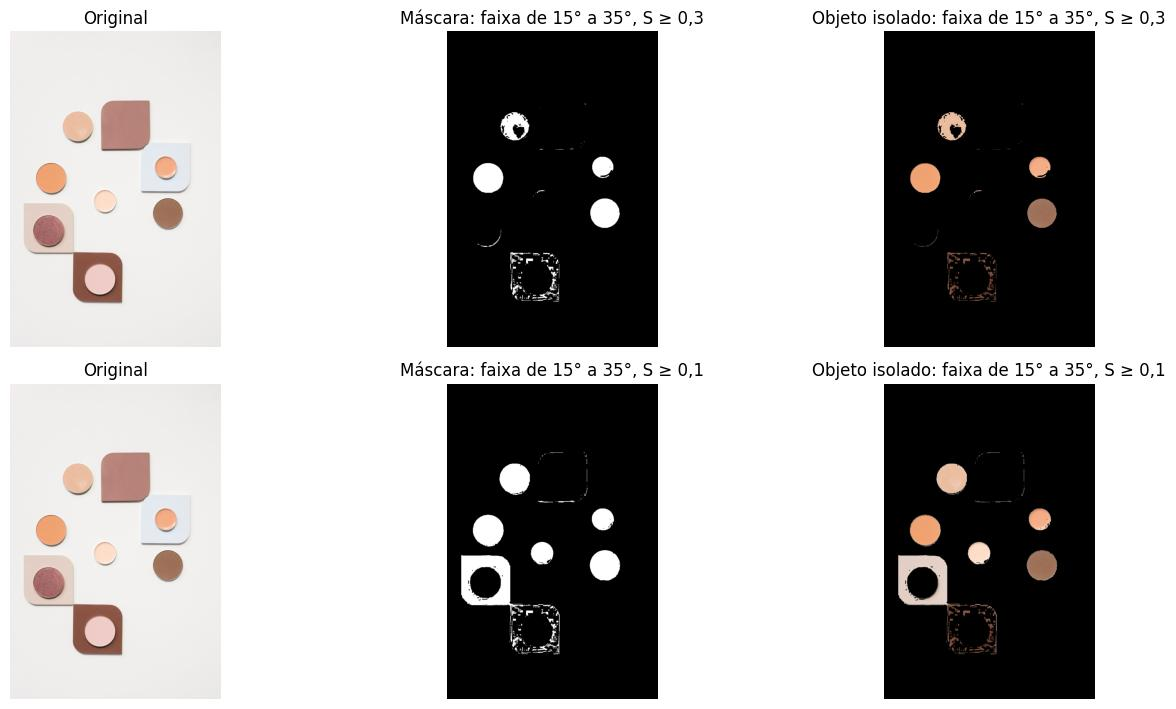

In [39]:
img_pastel = carregar("imagens/tons_pastel.jpg")
hsv_pastel = rgb_para_hsv(img_pastel)

fig, eixos = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1, 2]})
eixos[0].imshow(img_pastel)
eixos[0].set_title("Original")
eixos[1].imshow(hsv_pastel[..., 0], cmap="hsv", vmin=0, vmax=360)
eixos[1].set_title("H (matiz)")
eixos[2].imshow(hsv_pastel[..., 1], cmap="gray", vmin=0, vmax=1)
eixos[2].set_title("S (saturação)")
for eixo in eixos[:3]:
    eixo.axis("off")
histograma_h(hsv_pastel, s_min=0.1, eixo=eixos[3], titulo="Tons pastel")
plt.tight_layout()
plt.show()

mostrar_segmentacao(img_pastel, {
    "faixa de 15° a 35°, S ≥ 0,3": segmentar_hsv(hsv_pastel, 15, 35, s_min=0.3),
    "faixa de 15° a 35°, S ≥ 0,1": segmentar_hsv(hsv_pastel, 15, 35, s_min=0.1),
})

Quase todos os pixels coloridos caem num único monte, entre 0° e 30°. A imagem do H mostra duas famílias: os objetos rosados e marrom-arroxeados, de 0° a 15°, e os cor de pêssego, de 20° a 30°. Dentro de cada família, os objetos têm a mesma matiz.

Tentamos isolar os círculos cor de pêssego com a faixa de 15° a 35°:

- Com $s_{min} = 0{,}3$, os círculos mais pálidos somem ou ficam com buracos, porque a saturação deles é baixa, e o círculo marrom já entra junto com os de pêssego.
- Com $s_{min} = 0{,}1$, os círculos pálidos aparecem, mas entra também a placa bege. O marrom e o bege têm a mesma matiz do pêssego e só diferem no brilho ou na saturação.

Nenhuma faixa de matiz separa pêssego de marrom, porque no HSV os dois são o mesmo laranja, um claro e outro escuro. Para separar seria preciso usar também faixas de S e de V (por exemplo, V alto para o pêssego e V baixo para o marrom), e aí a segmentação volta a depender do brilho, que é o que a sombra altera.

### Outras limitações

- A faixa é escolhida à mão. Em cada imagem olhamos o histograma de H e escolhemos $h_{min}$, $h_{max}$, $s_{min}$ e $v_{min}$. Nos carretéis foi preciso ajustar os limites de cada cor para fugir da madeira, e uma faixa que funciona numa foto pode falhar em outra.
- Pixels escuros ou quase cinza não têm matiz confiável. Isso aconteceu na linha verde-escura dos carretéis (H = 352° numa linha verde) e no experimento de diminuir a luz, em que o $v_{min}$ descartou pixels com a matiz certa.
- A cor da luz conta. Uma sombra só multiplica os canais por $k$ quando a luz que sobra tem a mesma cor da luz direta. Ao ar livre, a sombra é iluminada pelo céu, que é azulado, e uma lâmpada amarela também desloca a matiz. Nas nossas fotos o deslocamento foi pequeno (cerca de 2° na parede amarela), mas existe.
- A máscara sai com buracos e pontos soltos, como nos carretéis e na maçã. A morfologia, que vimos no post 08 do blog, limpa esse tipo de máscara: a dilatação fecha buracos pequenos, e uma erosão seguida de dilatação remove pontos isolados. Ela pode ser aplicada depois da segmentação por cor, mas ficou fora do escopo deste tutorial.

<a id="secao8"></a>

## 8. Conclusão

Este tutorial saiu da escala de cinza, que usamos no resto da disciplina, e passou a trabalhar com cor. Primeiro mostramos que o cinza não separa objetos de cores diferentes, porque junta os três canais num número só. Depois mostramos que o RGB guarda a cor mas a mistura com o brilho, de modo que uma sombra muda os três canais. A conversão RGB → HSV seguiu as fórmulas de Smith (1978), pixel a pixel e depois com NumPy, e bateu com o `colorsys` e com o OpenCV em cerca de 250 mil cores. Com o HSV, segmentamos por faixa de matiz, com mínimos de saturação e valor. A faixa foi escolhida pelo histograma de H, e o vermelho, que passa pelo 0°, precisou de uma regra à parte. Por fim, comparamos com a segmentação por caixa em RGB.

A comparação da seção 6 deu o resultado mais claro. Com limites medidos na parte iluminada, a caixa RGB não encontrou nada da parte na sombra, nem na imagem sintética nem na parede amarela, e quando ampliamos a caixa para caber a sombra ela passou a pegar outros objetos e o chão. Com metade da luz, a máscara RGB ficou vazia e a HSV continuou praticamente igual (IoU = 0,997). A diferença vem de o HSV guardar o brilho só no V, enquanto a matiz quase não muda com a sombra.

O método tem limites, mostrados na seção 7: reflexos e pixels escuros ou pálidos não têm matiz confiável, objetos com a mesma matiz e brilho diferente não se separam, e a faixa precisa ser escolhida à mão em cada imagem.

Como continuação, daria para testar o modelo HSI, que calcula a intensidade como a média dos três canais em vez do máximo, aplicar a morfologia do post 08 para limpar as máscaras e escolher a faixa de matiz automaticamente, procurando os picos do histograma de H.

<a id="secao9"></a>

## 9. Uso de IA

Conforme o Comunicado FCI sobre conduta nas avaliações, declaramos as ferramentas de inteligência artificial usadas neste projeto.

- Claude (Anthropic), utilizando a ferramenta do Claude Code. O código do notebook foi implementado com auxílio. Os textos do tutorial também foram redigidos com o auxílio do Claude, a partir desse código e dos resultados que ele gerou, e foram revisados pelo grupo, João Guilherme e Luis Felipe. O Claude ajudou ainda a organizar o repositório.
- Gemini (Google), usado só para pesquisar fotos com licença livre a partir de descrições que escrevemos. Nenhuma imagem foi gerada por IA. Abrimos cada link, conferimos a página, o autor e a licença e baixamos o arquivo original do site (as fontes estão nas referências e em `imagens/README.md`).

O que a IA produziu foi verificado assim:

- A conversão RGB → HSV é testada no próprio notebook com `assert`: cores conhecidas, versão de um pixel contra a versão vetorizada e comparação com o `colorsys` e o OpenCV em cerca de 250 mil cores (seção 4).
- A segmentação é medida contra o gabarito da imagem sintética (IoU) e, nas fotos, em regiões que sabemos ser objeto ou fundo.
- Cada número citado no texto foi conferido com a saída do código, e o notebook foi executado do início ao fim antes da entrega.
- Estudamos as fórmulas e as funções para conseguir explicá-las no vídeo.

<a id="secao10"></a>

## 10. Referências

**Bibliografia**

- GONZALEZ, R. C.; WOODS, R. E. *Processamento digital de imagens*. 3. ed. São Paulo: Pearson Prentice Hall, 2010. Capítulo 6 (processamento de imagens coloridas).
- SMITH, A. R. Color gamut transform pairs. *ACM SIGGRAPH Computer Graphics*, v. 12, n. 3, p. 12-19, 1978. DOI: 10.1145/965139.807361.

**Material da disciplina**

- KISHIMOTO, A. *Fundamentos da imagem digital 01*. Slides da disciplina Computação Visual. São Paulo: Universidade Presbiteriana Mackenzie, 2026.
- KISHIMOTO, A. *Histograma*. Slides da disciplina Computação Visual. São Paulo: Universidade Presbiteriana Mackenzie, 2026.
- SANTOS, J. G. M. O. Limiarização e morfologia: separando objetos do fundo. *Blog-Comp-Visual*, 2026. Disponível em: https://github.com/Joaogmos/Blog-Comp-Visual. Acesso em: 15 out. 2026.

**Bibliotecas e documentação**

- HARRIS, C. R. et al. Array programming with NumPy. *Nature*, v. 585, p. 357-362, 2020.
- HUNTER, J. D. Matplotlib: a 2D graphics environment. *Computing in Science & Engineering*, v. 9, n. 3, p. 90-95, 2007.
- CLARK, A. et al. *Pillow (PIL Fork) documentation*. Disponível em: https://pillow.readthedocs.io. Acesso em: 15 out. 2026.
- PYTHON SOFTWARE FOUNDATION. *colorsys: conversions between color systems*. Disponível em: https://docs.python.org/3/library/colorsys.html. Acesso em: 15 out. 2026.
- OPENCV. *Color conversions*. Disponível em: https://docs.opencv.org/4.x/de/d25/imgproc_color_conversions.html. Acesso em: 15 out. 2026.

**Imagens de teste** (Pexels, uso livre pela Licença Pexels: https://www.pexels.com/license/)

- HAZELWOOD, S. *A close-up shot of reels of thread*. Pexels. Disponível em: https://www.pexels.com/photo/a-close-up-shot-of-reels-of-thread-7227389/. Acesso em: 15 out. 2026.
- VAN DER WOLF, J. *Shadow on yellow wall*. Pexels. Disponível em: https://www.pexels.com/photo/shadow-on-yellow-wall-18925117/. Acesso em: 15 out. 2026.
- NIKITIN, N. *Shadow on a red wall*. Pexels. Disponível em: https://www.pexels.com/photo/shadow-on-a-red-wall-10102272/. Acesso em: 15 out. 2026.
- LAKER. *Ripe shiny red apple placed on yellow surface*. Pexels. Disponível em: https://www.pexels.com/photo/ripe-shiny-red-apple-placed-on-yellow-surface-6157055/. Acesso em: 15 out. 2026.
- LACH, R. *Warm pastel colors in geometric figures on white background*. Pexels. Disponível em: https://www.pexels.com/photo/warm-pastel-colors-in-geometric-figures-on-white-background-8776817/. Acesso em: 15 out. 2026.